In [6]:
# @title
# =============================================================================
# BLOCK 0: GLOBAL SETUP, RIEMANNIAN PRIMITIVES & VISUAL CONFIGURATION
# =============================================================================
import os
import math
from typing import Any, Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import jax
import jax.numpy as jnp
from jax import random

try:
    import jax.extend.core as jec
    if not hasattr(jax.core, "get_opaque_trace_state") and hasattr(jec, "get_opaque_trace_state"):
        jax.core.get_opaque_trace_state = jec.get_opaque_trace_state
except Exception:
    pass

import flax.linen as nn
from flax.training import train_state
import optax

DEVICES = jax.devices()
SEED: int = 42
DTYPE: jnp.dtype = jnp.bfloat16

D_MODEL: int = 128
D_INTER: int = 384
M_MODES: int = 4
N_LAYERS: int = 2
BATCH_SIZE: int = 512
LEARNING_RATE: float = 1e-3

plt.style.use("dark_background")
plt.rcParams["figure.facecolor"] = "#000000"
plt.rcParams["axes.facecolor"] = "#000000"
plt.rcParams["savefig.facecolor"] = "#000000"
plt.rcParams["text.color"] = "#ffffff"
plt.rcParams["axes.labelcolor"] = "#ffffff"
plt.rcParams["xtick.color"] = "#bbbbbb"
plt.rcParams["ytick.color"] = "#bbbbbb"
plt.rcParams["grid.color"] = "#333333"


def to_unit_sphere(x: jnp.ndarray, eps: float = 1e-7) -> jnp.ndarray:
    norm = jnp.sqrt(jnp.sum(x.astype(jnp.float32)**2, axis=-1, keepdims=True) + eps**2)
    return (x.astype(jnp.float32) / norm).astype(x.dtype)


def lie_bivector_action(u: jnp.ndarray, v: jnp.ndarray, x: jnp.ndarray) -> jnp.ndarray:
    u_f, v_f, x_f = u.astype(jnp.float32), v.astype(jnp.float32), x.astype(jnp.float32)
    vx = jnp.sum(v_f * x_f, axis=-1, keepdims=True)
    ux = jnp.sum(u_f * x_f, axis=-1, keepdims=True)
    return (vx * u_f - ux * v_f).astype(x.dtype)


def unit_riemannian_expmap(
    x: jnp.ndarray,
    v_tangent: jnp.ndarray,
    max_angle: float = math.pi / 2.0,
    eps: float = 1e-6
) -> jnp.ndarray:
    x_f, v_f = x.astype(jnp.float32), v_tangent.astype(jnp.float32)
    v_norm = jnp.sqrt(jnp.sum(v_f**2, axis=-1, keepdims=True) + eps**2)
    v_norm_clamped = jnp.clip(v_norm, 0.0, max_angle)

    sinc = jnp.where(v_norm > eps, jnp.sin(v_norm_clamped) / v_norm, 1.0)
    x_next = jnp.cos(v_norm_clamped) * x_f + sinc * v_f

    norm_next = jnp.sqrt(jnp.sum(x_next**2, axis=-1, keepdims=True) + eps**2)
    return (x_next / norm_next).astype(x.dtype)


class PureLieVolterraFlowLayer(nn.Module):
    d_model: int = D_MODEL
    d_inter: int = D_INTER
    m_modes: int = M_MODES
    block_size: int = 3
    dtype: jnp.dtype = DTYPE

    def setup(self) -> None:
        t = jnp.arange(self.block_size, dtype=jnp.float32)
        m = jnp.arange(self.m_modes, dtype=jnp.float32)[None, :]
        t_norm = (2.0 * t[:, None] / max(self.block_size - 1, 1)) - 1.0
        cheb = jnp.cos(m * jnp.arccos(jnp.clip(t_norm, -1.0 + 1e-6, 1.0 - 1e-6)))

        x_s = (2.0 * t + 1.0) / (2.0 * self.block_size)
        w_cheb = 1.0 / jnp.sqrt(x_s * (1.0 - x_s) + 1e-5)
        w_cheb = (w_cheb / jnp.mean(w_cheb))[:, None]

        self.base_phi = cheb
        self.base_psi = cheb * w_cheb

        t_grid = t[:, None]
        s_grid = t[None, :]
        self.delta_ts = jnp.maximum(t_grid - s_grid, 0.0)
        self.causal_mask = jnp.tril(jnp.ones((self.block_size, self.block_size), dtype=jnp.bool_))

    @nn.compact
    def __call__(self, x: jnp.ndarray, return_internals: bool = False) -> Any:
        b, t, d = x.shape

        w_curr = nn.Dense(self.d_model, use_bias=False, dtype=self.dtype, name="w_curr")
        j_current = w_curr(x)

        init_gammas = jnp.linspace(math.log(0.005), math.log(0.20), self.m_modes)
        log_gamma = self.param("log_gamma", lambda rng: init_gammas)
        lambdas = self.param("lambdas", lambda rng: jnp.ones((self.m_modes,), dtype=jnp.float32) / math.sqrt(self.m_modes))

        phi = self.base_phi[:t, :]
        psi = self.base_psi[:t, :]

        gamma = jnp.clip(jnp.exp(log_gamma), 1e-4, 2.0)
        decay = jnp.exp(-gamma[:, None, None] * self.delta_ts[:t, :t][None, :, :])
        base_kernel = jnp.einsum("tm,sm->mst", phi, psi)
        causal_kernel = jnp.sum(lambdas[:, None, None] * base_kernel * decay, axis=0)
        causal_kernel = jnp.where(self.causal_mask[:t, :t], causal_kernel, 0.0)

        h_memory = jnp.matmul(causal_kernel.astype(self.dtype)[None, :, :], j_current)

        w_u = nn.Dense(self.d_inter, use_bias=False, dtype=self.dtype, name="w_u")
        w_v = nn.Dense(self.d_inter, use_bias=False, dtype=self.dtype, name="w_v")
        w_proj = nn.Dense(self.d_model, use_bias=False, dtype=self.dtype, name="w_proj")

        u_field = nn.silu(w_u(x))
        v_field = nn.silu(w_v(h_memory))

        interaction = u_field * v_field
        force_direction = w_proj(interaction)

        v_tangent = lie_bivector_action(force_direction, force_direction * 0.5 + x, x)
        eta = self.param("tangent_scale", lambda rng: jnp.array(0.05, dtype=jnp.float32))
        x_next = unit_riemannian_expmap(x, v_tangent * eta)

        if return_internals:
            return x_next, interaction
        return x_next


def build_decay_mask(params: Dict[str, Any]) -> Any:
    def should_decay(path, param):
        path_str = "/".join([str(p.key) if hasattr(p, 'key') else str(p) for p in path])
        if any(nd in path_str for nd in ["log_tau", "log_gamma", "lambdas", "tangent_scale", "bias"]):
            return False
        return True

    return jax.tree_util.tree_map_with_path(should_decay, params)


print(f"[SETUP] Hardware: {DEVICES[0].device_kind.upper()} | Backend: {jax.default_backend()} | Precision: bfloat16")

[SETUP] Hardware: NVIDIA L4 | Backend: gpu | Precision: bfloat16


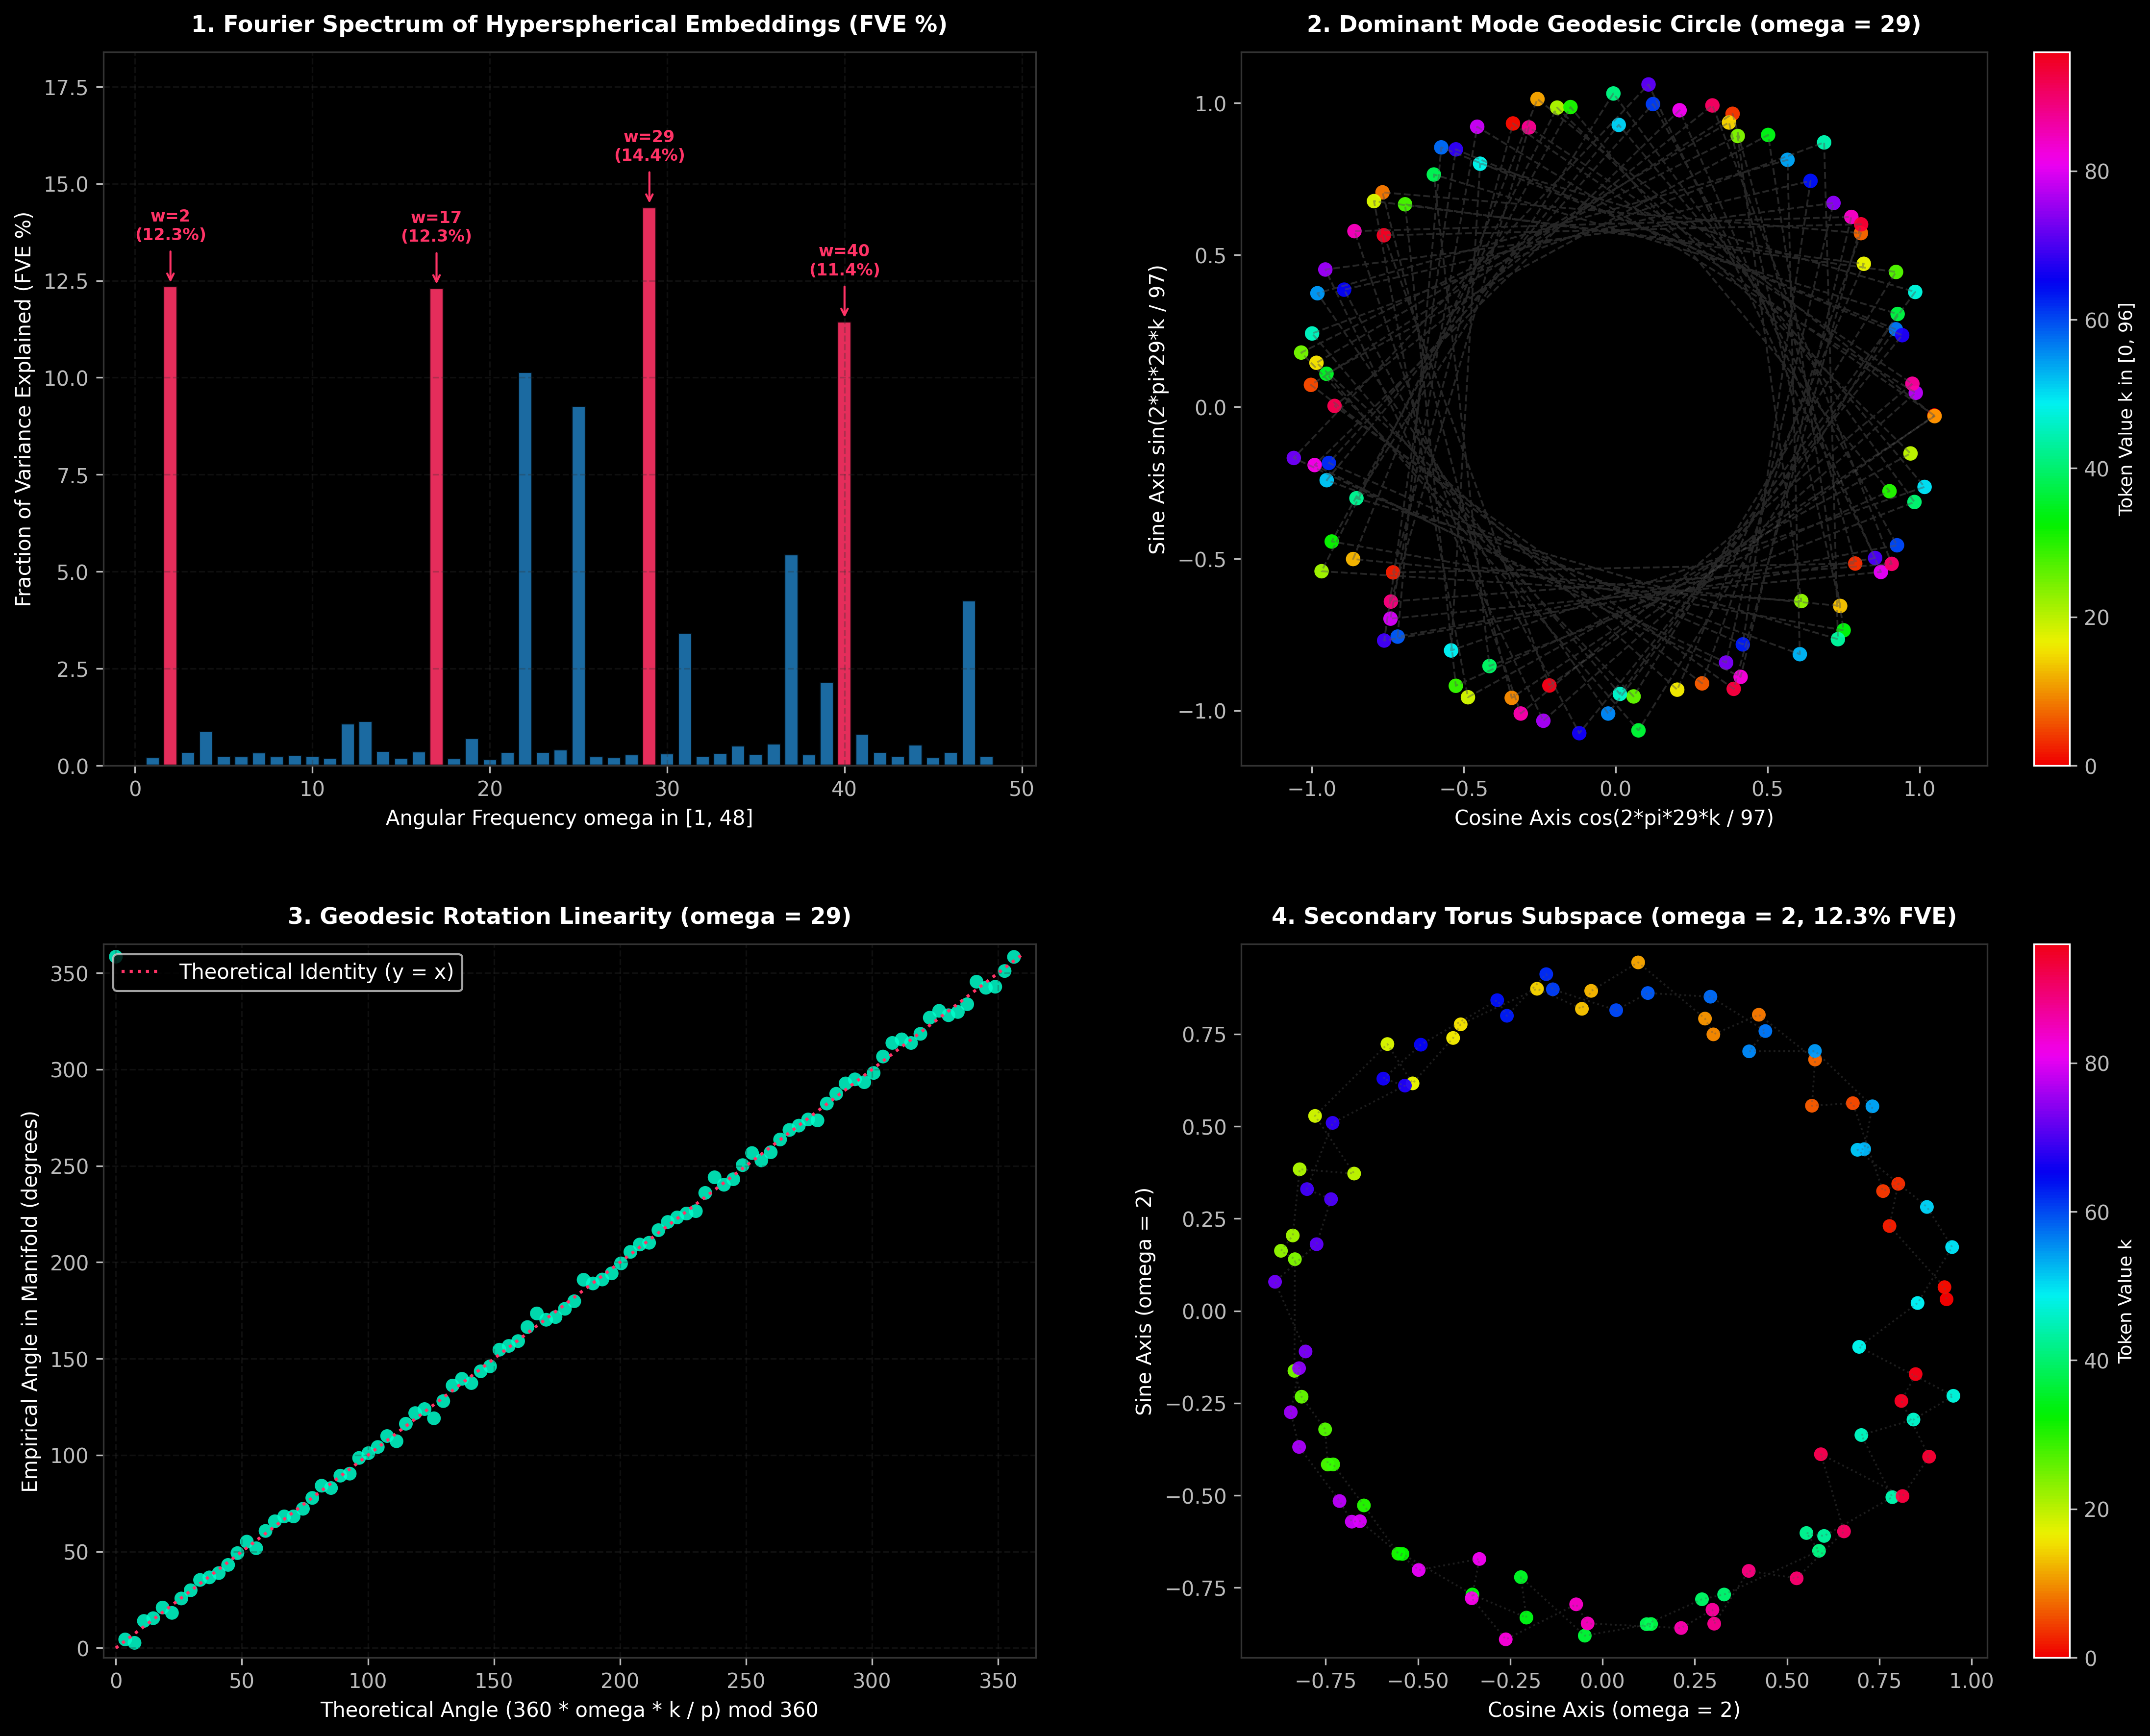

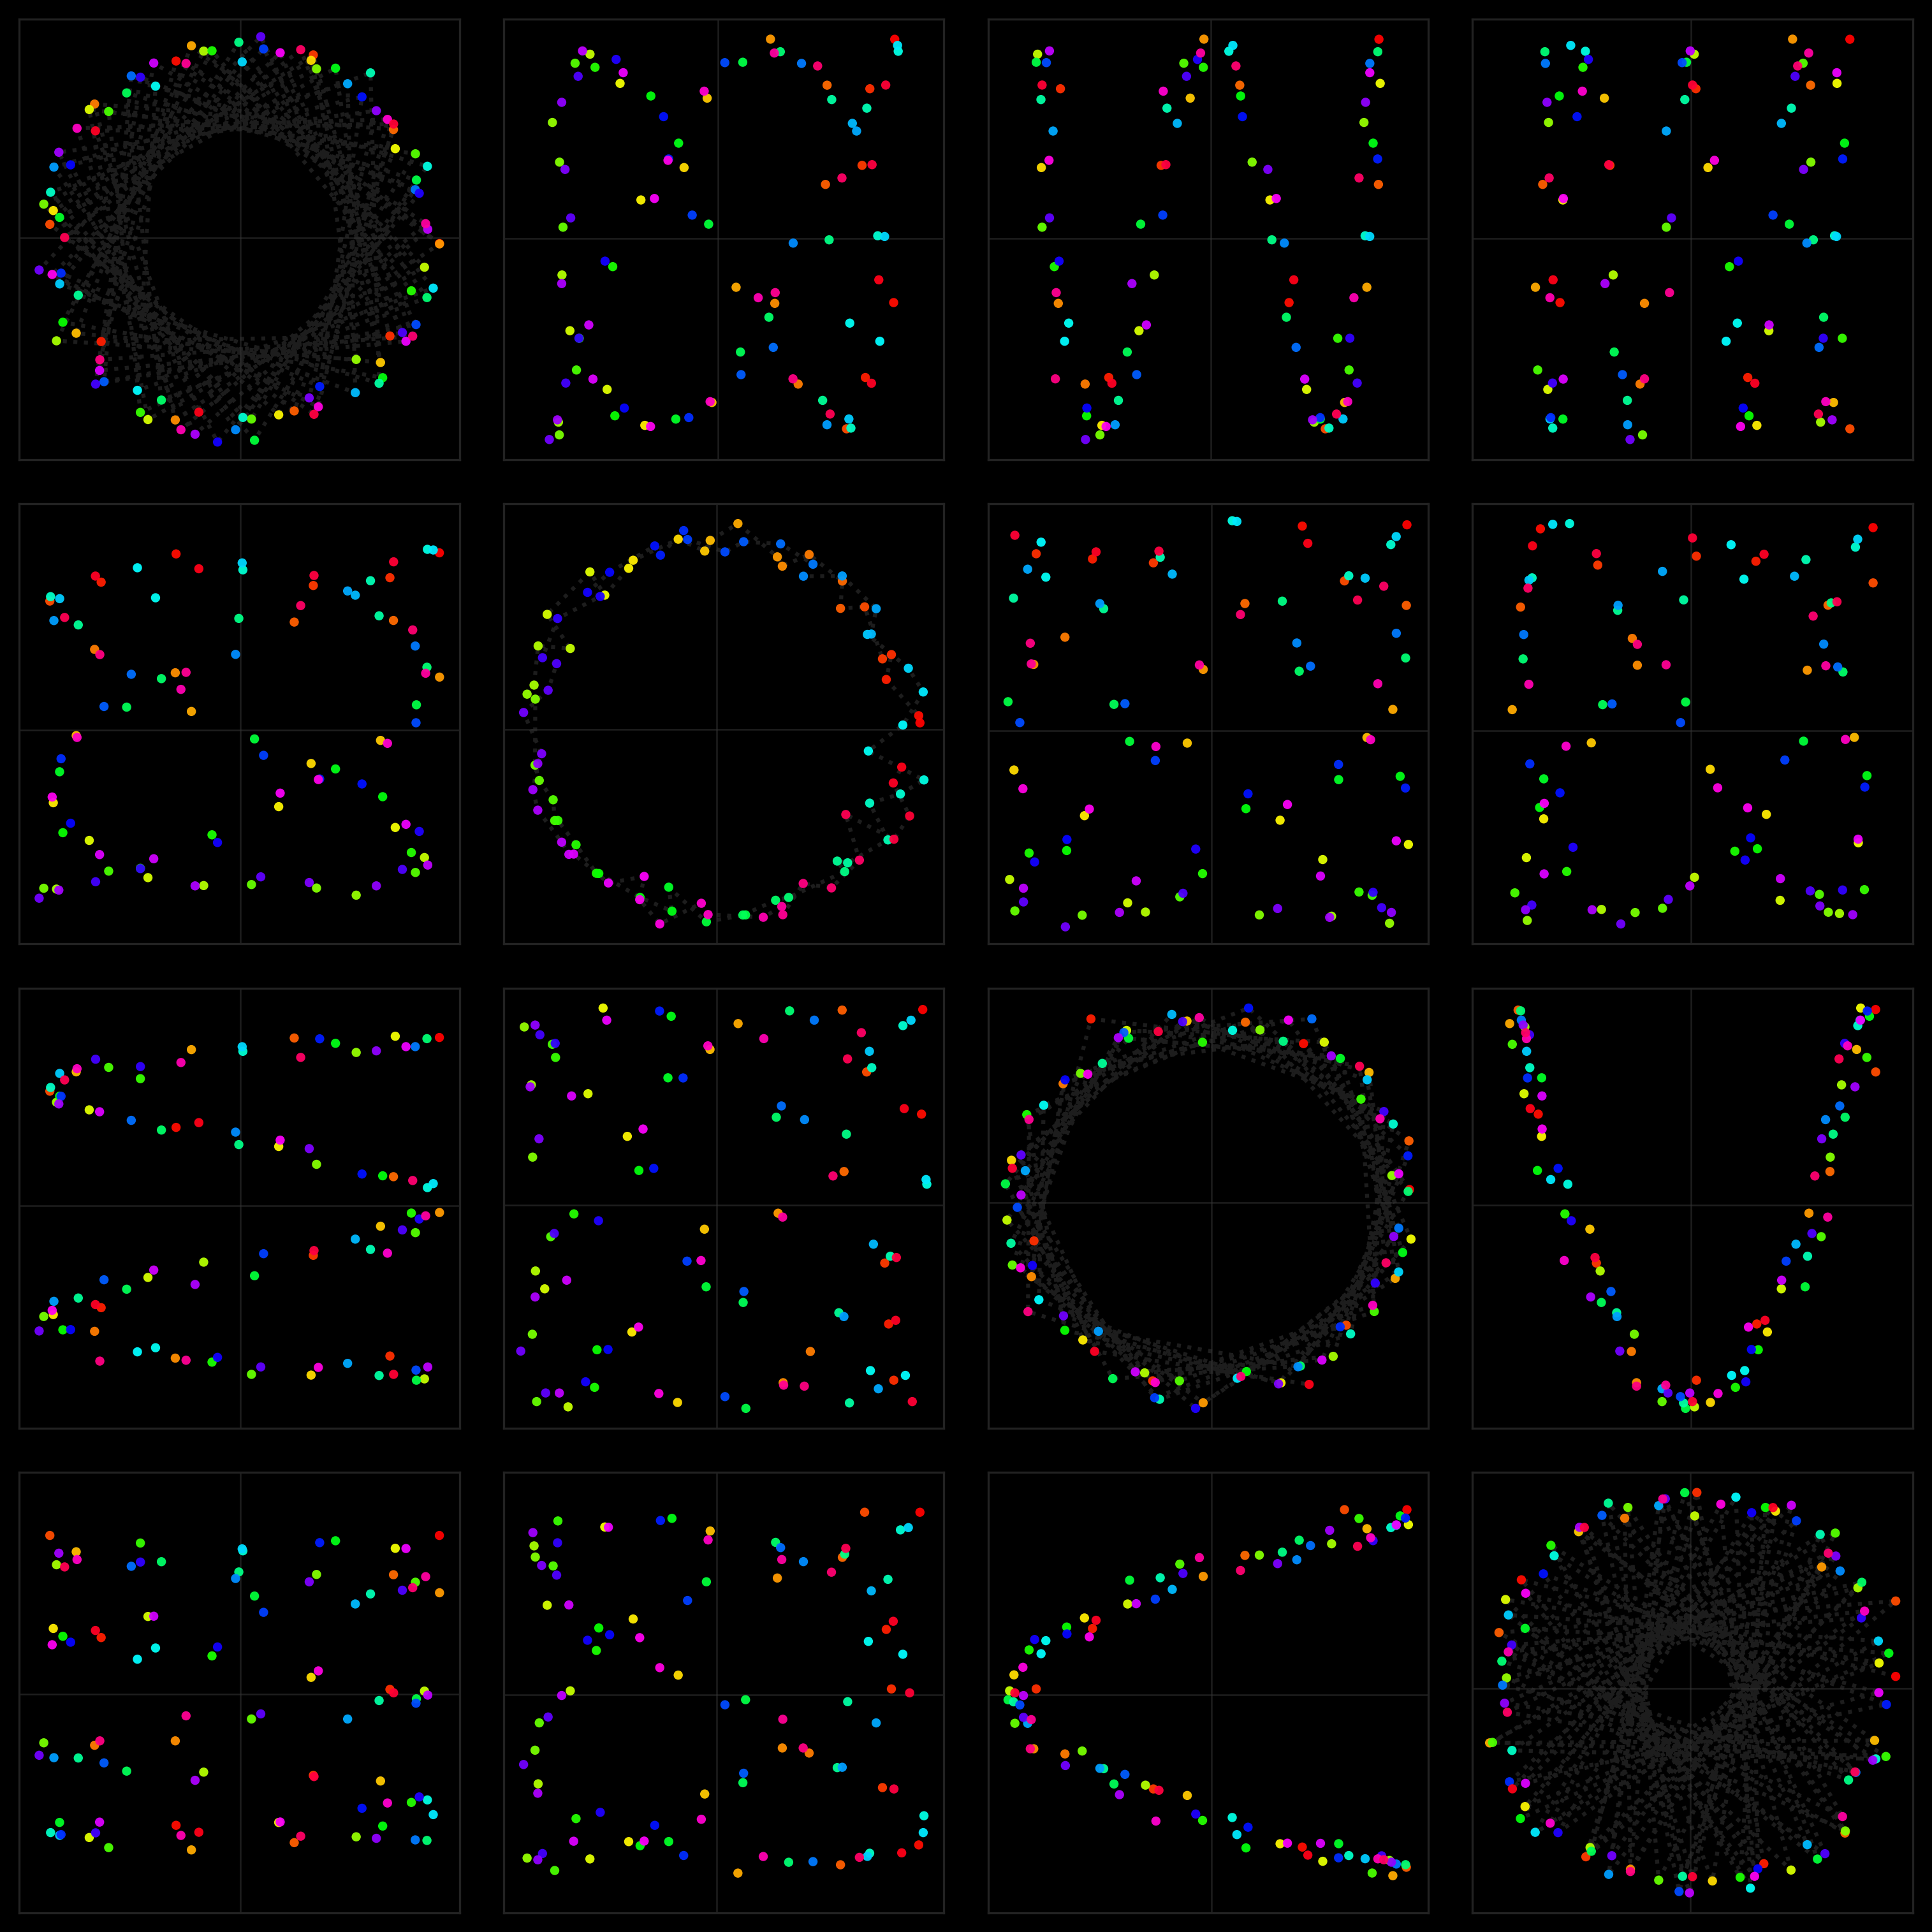

/tmp/ipykernel_1156/3673858568.py:278: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fve = float(energy / var)


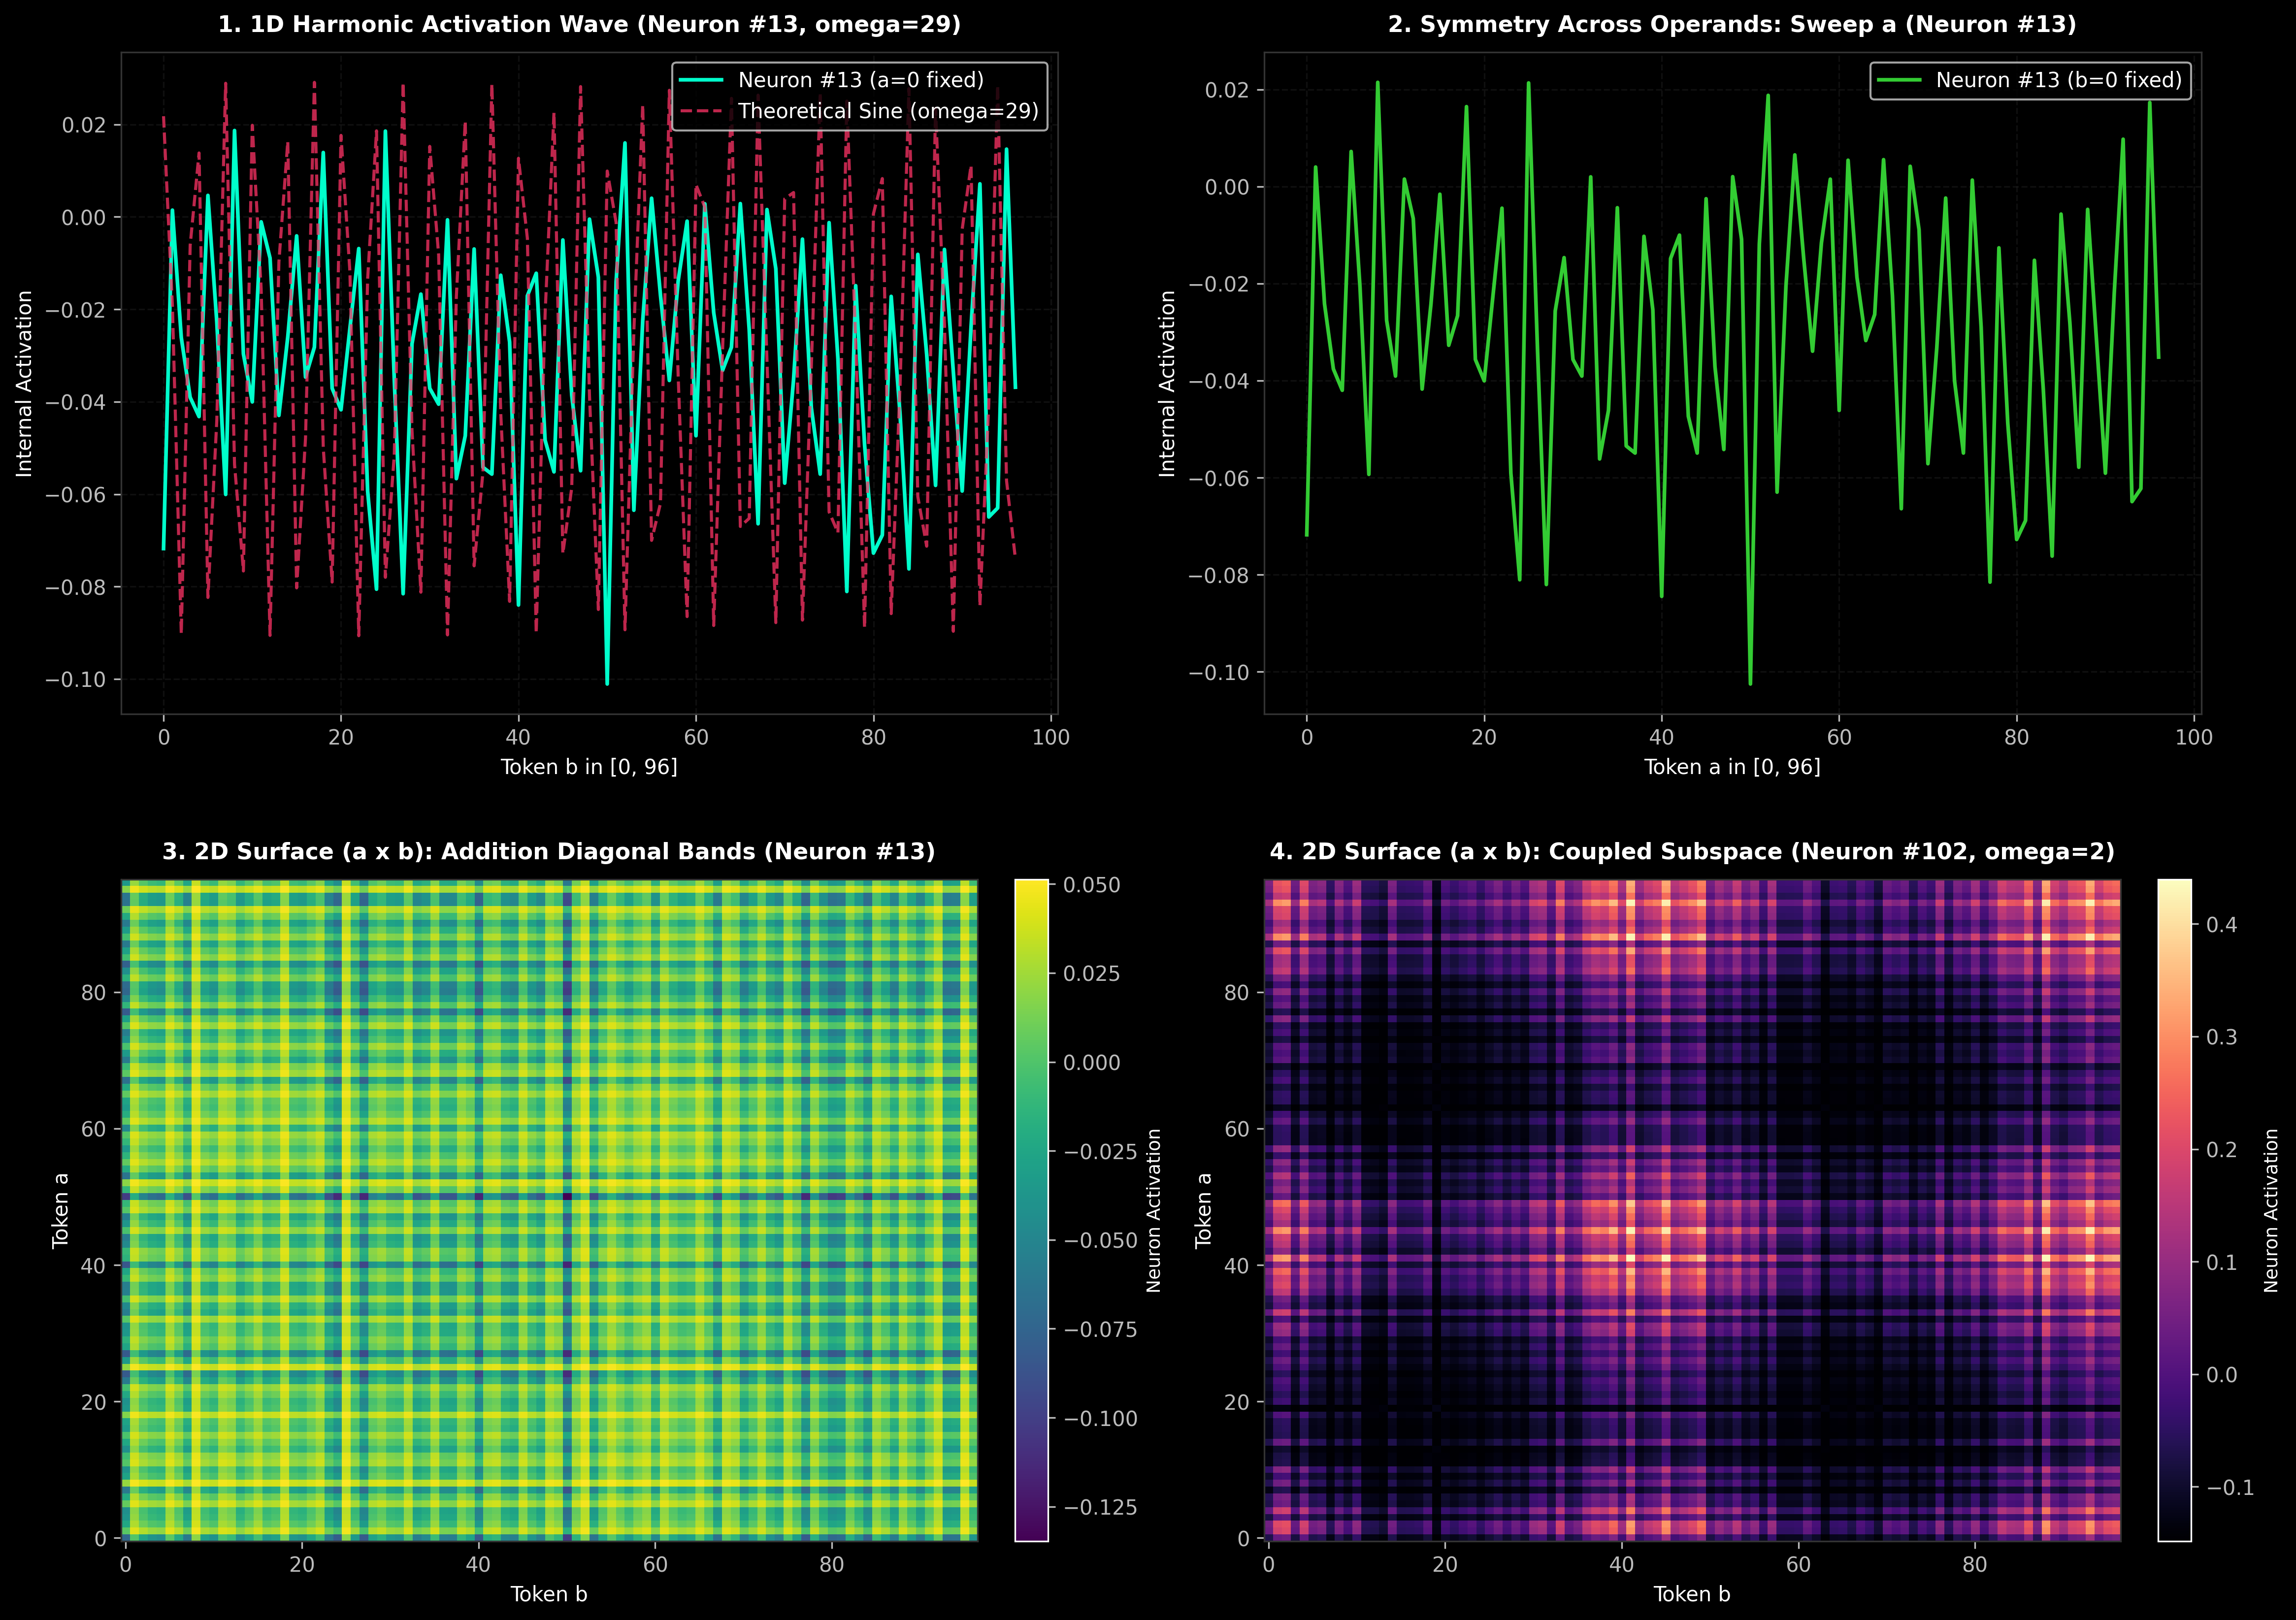

In [7]:
# @title
# =============================================================================
# BLOCK 1: MODULAR ADDITION (Z_97) - TRAINING & MECHANISTIC VISUALIZATIONS
# =============================================================================
P_ADD: int = 97
MAX_STEPS_ADD: int = 2500
WEIGHT_DECAY_ADD: float = 0.1


class PLVFModularAdditionModel(nn.Module):
    vocab_size: int = P_ADD + 1
    target_classes: int = P_ADD
    d_model: int = D_MODEL
    d_inter: int = D_INTER
    n_layers: int = N_LAYERS
    m_modes: int = M_MODES
    block_size: int = 3
    dtype: jnp.dtype = DTYPE

    @nn.compact
    def __call__(self, idx: jnp.ndarray, return_internals: bool = False) -> Any:
        tok_embed = self.param("token_emb", nn.initializers.normal(stddev=0.02), (self.vocab_size, self.d_model), self.dtype)
        tok_u = to_unit_sphere(tok_embed)
        x = tok_u[idx]

        internals = []
        for i in range(self.n_layers):
            layer = PureLieVolterraFlowLayer(
                d_model=self.d_model,
                d_inter=self.d_inter,
                m_modes=self.m_modes,
                block_size=self.block_size,
                dtype=self.dtype,
                name=f"flow_{i}"
            )
            if return_internals:
                x, act = layer(x, return_internals=True)
                internals.append(act)
            else:
                x = layer(x)

        last_state = to_unit_sphere(x[:, -1, :])
        target_vocab_u = tok_u[:self.target_classes, :]
        cos_sim = jnp.matmul(last_state.astype(jnp.float32), target_vocab_u.astype(jnp.float32).T)

        log_tau = self.param("log_tau", lambda rng: jnp.array(math.log(15.0), dtype=jnp.float32))
        tau = jnp.clip(jnp.exp(log_tau), 1.0, 40.0)
        logits = tau * cos_sim

        if return_internals:
            return logits, cos_sim, internals, tok_u
        return logits, cos_sim, tok_u


def get_modular_addition_data(seed: int = 42) -> Tuple[jnp.ndarray, jnp.ndarray, jnp.ndarray, jnp.ndarray]:
    rng = np.random.default_rng(seed)
    pairs = [(a, b) for a in range(P_ADD) for b in range(P_ADD)]
    rng.shuffle(pairs)

    n_train = len(pairs) // 2
    train_pairs, val_pairs = pairs[:n_train], pairs[n_train:]

    def build(pair_list):
        x = np.zeros((len(pair_list), 3), dtype=np.int32)
        y = np.zeros((len(pair_list),), dtype=np.int32)
        for i, (a, b) in enumerate(pair_list):
            x[i, 0], x[i, 1], x[i, 2] = a, b, P_ADD
            y[i] = (a + b) % P_ADD
        return jnp.array(x), jnp.array(y)

    x_train, y_train = build(train_pairs)
    x_val, y_val = build(val_pairs)
    return x_train, y_train, x_val, y_val


# -----------------------------------------------------------------------------
# 1. Canonical Training Loop
# -----------------------------------------------------------------------------
x_train_add, y_train_add, x_val_add, y_val_add = get_modular_addition_data(seed=SEED)
model_add = PLVFModularAdditionModel()

init_rng = random.PRNGKey(SEED)
dummy_x = jnp.ones((BATCH_SIZE, 3), dtype=jnp.int32)
params_add = model_add.init(init_rng, dummy_x)["params"]

decay_mask_add = build_decay_mask(params_add)
tx_add = optax.chain(
    optax.clip_by_global_norm(1.0),
    optax.adamw(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY_ADD, b1=0.9, b2=0.98, mask=decay_mask_add)
)
state_add = train_state.TrainState.create(apply_fn=model_add.apply, params=params_add, tx=tx_add)


@jax.jit
def train_step_add(state: train_state.TrainState, x: jnp.ndarray, y: jnp.ndarray):
    def loss_fn(p):
        logits, _, _ = state.apply_fn({"params": p}, x)
        loss = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=y).mean()
        return loss, logits
    (loss, logits), grads = jax.value_and_grad(loss_fn, has_aux=True)(state.params)
    acc = jnp.mean(jnp.argmax(logits, axis=-1) == y)
    return state.apply_gradients(grads=grads), loss, acc


train_rng = random.PRNGKey(SEED)
n_train_add = len(x_train_add)

for step in range(1, MAX_STEPS_ADD + 1):
    train_rng, sub_rng = random.split(train_rng)
    idx = random.randint(sub_rng, shape=(BATCH_SIZE,), minval=0, maxval=n_train_add)
    state_add, loss_val, acc_val = train_step_add(state_add, x_train_add[idx], y_train_add[idx])

    if step % 250 == 0:
        val_lg, _, _ = state_add.apply_fn({"params": state_add.params}, x_val_add)
        val_acc = float(jnp.mean(jnp.argmax(val_lg, axis=-1) == y_val_add))
        if val_acc >= 0.9999:
            break

_, _, tok_u_add = state_add.apply_fn({"params": state_add.params}, jnp.ones((1, 3), dtype=jnp.int32))
W_E_add = np.array(tok_u_add[:P_ADD], dtype=np.float64)

# -----------------------------------------------------------------------------
# 2. Fourier Spectrum & SO(2) Harmonic Circles (Figure 1)
# -----------------------------------------------------------------------------
W_E_centered = W_E_add - np.mean(W_E_add, axis=0, keepdims=True)
total_variance = np.sum(W_E_centered**2)

max_freq_add = (P_ADD - 1) // 2
k_vec = np.arange(P_ADD)[:, None]
fves_add = []
projections_2d_add = {}

for omega in range(1, max_freq_add + 1):
    cos_basis = np.sqrt(2.0 / P_ADD) * np.cos(2.0 * np.pi * omega * k_vec / P_ADD)
    sin_basis = np.sqrt(2.0 / P_ADD) * np.sin(2.0 * np.pi * omega * k_vec / P_ADD)
    coeff_cos = cos_basis.T @ W_E_centered
    coeff_sin = sin_basis.T @ W_E_centered
    energy = np.sum(coeff_cos**2) + np.sum(coeff_sin**2)
    fves_add.append((energy / total_variance) * 100.0)

    coords_x = W_E_centered @ coeff_cos.T
    coords_y = W_E_centered @ coeff_sin.T
    projections_2d_add[omega] = np.hstack([coords_x, coords_y])

omegas_add = np.arange(1, max_freq_add + 1)
sorted_idx = np.argsort(fves_add)[::-1]
top_4_omegas = [int(omegas_add[i]) for i in sorted_idx[:4]]

fig1, axes1 = plt.subplots(2, 2, figsize=(16, 13), facecolor="#000000", dpi=300)
fig1.subplots_adjust(wspace=0.22, hspace=0.25, left=0.06, right=0.94, top=0.92, bottom=0.08)

ax1 = axes1[0, 0]
ax1.set_facecolor("#000000")
bar_colors = ["#ff3366" if w in top_4_omegas else "#1f77b4" for w in omegas_add]
ax1.bar(omegas_add, fves_add, color=bar_colors, width=0.8, edgecolor="#000000", alpha=0.9)
ax1.set_title("1. Fourier Spectrum of Hyperspherical Embeddings (FVE %)", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("Angular Frequency omega in [1, 48]", fontsize=10)
ax1.set_ylabel("Fraction of Variance Explained (FVE %)", fontsize=10)
for w in top_4_omegas:
    val = fves_add[w - 1]
    ax1.annotate(f"w={w}\n({val:.1f}%)", xy=(w, val), xytext=(w, val + 1.2),
                 ha="center", fontsize=8, fontweight="bold", color="#ff3366",
                 arrowprops=dict(arrowstyle="->", color="#ff3366"))
ax1.set_ylim(0, max(fves_add) + 4)
for spine in ax1.spines.values():
    spine.set_color("#333333")
ax1.grid(True, linestyle="--", alpha=0.3)

ax2 = axes1[0, 1]
ax2.set_facecolor("#000000")
w1 = top_4_omegas[0]
pts1 = projections_2d_add[w1]
tokens_vec = np.arange(P_ADD)
ax2.plot(pts1[:, 0], pts1[:, 1], color="#555555", alpha=0.45, linestyle="--", linewidth=0.9)
ax2.plot([pts1[-1, 0], pts1[0, 0]], [pts1[-1, 1], pts1[0, 1]], color="#555555", alpha=0.45, linestyle="--", linewidth=0.9)
sc1 = ax2.scatter(pts1[:, 0], pts1[:, 1], c=tokens_vec, cmap=plt.cm.hsv, s=50, alpha=0.95, edgecolors="none")
ax2.set_title(f"2. Dominant Mode Geodesic Circle (omega = {w1})", fontsize=11, fontweight="bold", pad=10)
ax2.set_xlabel(f"Cosine Axis cos(2*pi*{w1}*k / 97)", fontsize=10)
ax2.set_ylabel(f"Sine Axis sin(2*pi*{w1}*k / 97)", fontsize=10)
ax2.set_aspect("equal", adjustable="datalim")
for spine in ax2.spines.values():
    spine.set_color("#333333")
cbar1 = plt.colorbar(sc1, ax=ax2)
cbar1.set_label("Token Value k in [0, 96]", fontsize=9)

ax3 = axes1[1, 0]
ax3.set_facecolor("#000000")
angles_empirical = (np.degrees(np.arctan2(pts1[:, 1], pts1[:, 0])) + 360.0) % 360.0
angles_theoretical = (360.0 * w1 * tokens_vec / P_ADD) % 360.0
ax3.scatter(angles_theoretical, angles_empirical, color="#00ffcc", s=45, alpha=0.85, edgecolors="none")
ax3.plot([0, 360], [0, 360], color="#ff3366", linestyle=":", linewidth=1.5, label="Theoretical Identity (y = x)")
ax3.set_title(f"3. Geodesic Rotation Linearity (omega = {w1})", fontsize=11, fontweight="bold", pad=10)
ax3.set_xlabel("Theoretical Angle (360 * omega * k / p) mod 360", fontsize=10)
ax3.set_ylabel("Empirical Angle in Manifold (degrees)", fontsize=10)
ax3.set_xlim(-5, 365)
ax3.set_ylim(-5, 365)
ax3.legend(loc="upper left")
for spine in ax3.spines.values():
    spine.set_color("#333333")
ax3.grid(True, linestyle="--", alpha=0.3)

ax4 = axes1[1, 1]
ax4.set_facecolor("#000000")
w2 = top_4_omegas[1]
pts2 = projections_2d_add[w2]
ax4.plot(pts2[:, 0], pts2[:, 1], color="#555555", alpha=0.35, linestyle=":", linewidth=0.9)
sc2 = ax4.scatter(pts2[:, 0], pts2[:, 1], c=tokens_vec, cmap=plt.cm.hsv, s=45, alpha=0.95, edgecolors="none")
ax4.set_title(f"4. Secondary Torus Subspace (omega = {w2}, {fves_add[w2-1]:.1f}% FVE)", fontsize=11, fontweight="bold", pad=10)
ax4.set_xlabel(f"Cosine Axis (omega = {w2})", fontsize=10)
ax4.set_ylabel(f"Sine Axis (omega = {w2})", fontsize=10)
ax4.set_aspect("equal", adjustable="datalim")
for spine in ax4.spines.values():
    spine.set_color("#333333")
cbar2 = plt.colorbar(sc2, ax=ax4)
cbar2.set_label("Token Value k", fontsize=9)

plt.show()

# -----------------------------------------------------------------------------
# 3. Torus Matrix 4x4 (Figure 2)
# -----------------------------------------------------------------------------
projections_4modes = [projections_2d_add[w] for w in top_4_omegas]

fig2, axes2 = plt.subplots(4, 4, figsize=(11, 11), facecolor="#000000", dpi=300)
fig2.subplots_adjust(wspace=0.10, hspace=0.10, left=0.05, right=0.95, top=0.95, bottom=0.05)

for i in range(4):
    for j in range(4):
        ax = axes2[i, j]
        ax.set_facecolor("#000000")

        if i == j:
            pts = projections_4modes[i]
            ax.plot(pts[:, 0], pts[:, 1], color="#555555", alpha=0.35, linestyle=":", zorder=2)
            ax.scatter(pts[:, 0], pts[:, 1], c=tokens_vec, cmap=plt.cm.hsv, s=12, alpha=0.95, edgecolors="none", zorder=3)
        else:
            xi = projections_4modes[i][:, 0]
            xj = projections_4modes[j][:, 0]
            ax.scatter(xj, xi, c=tokens_vec, cmap=plt.cm.hsv, s=12, alpha=0.95, edgecolors="none", zorder=3)

        ax.axhline(0, color="#333333", linestyle="-", linewidth=0.6, alpha=0.6)
        ax.axvline(0, color="#333333", linestyle="-", linewidth=0.6, alpha=0.6)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_aspect("equal", adjustable="datalim")
        for spine in ax.spines.values():
            spine.set_color("#222222")

plt.show()

# -----------------------------------------------------------------------------
# 4. Mechanistic Neuron Activation Probing (Figure 3)
# -----------------------------------------------------------------------------
grid_x = np.zeros((P_ADD * P_ADD, 3), dtype=np.int32)
for a in range(P_ADD):
    for b in range(P_ADD):
        grid_x[a * P_ADD + b] = [a, b, P_ADD]

all_acts = []
for i in range(0, len(grid_x), 1024):
    bx = jnp.array(grid_x[i : i + 1024])
    _, _, internals, _ = state_add.apply_fn({"params": state_add.params}, bx, return_internals=True)
    act_t2 = np.array(internals[0][:, 2, :], dtype=np.float32)
    all_acts.append(act_t2)

acts_grid = np.concatenate(all_acts, axis=0).reshape(P_ADD, P_ADD, D_INTER)

neuron_periodicity = []
for n_idx in range(D_INTER):
    profile = acts_grid[0, :, n_idx]
    profile_c = profile - np.mean(profile)
    var = np.sum(profile_c**2) + 1e-7

    best_fve, best_w = 0.0, 1
    for w in range(1, max_freq_add + 1):
        cb = np.sqrt(2.0 / P_ADD) * np.cos(2.0 * np.pi * w * k_vec / P_ADD)
        sb = np.sqrt(2.0 / P_ADD) * np.sin(2.0 * np.pi * w * k_vec / P_ADD)
        energy = (cb.T @ profile_c)**2 + (sb.T @ profile_c)**2
        fve = float(energy / var)
        if fve > best_fve:
            best_fve = fve
            best_w = w
    neuron_periodicity.append((n_idx, best_w, best_fve))

neuron_periodicity.sort(key=lambda x: x[2], reverse=True)
top_n, top_n_w, top_n_fve = neuron_periodicity[0]
sec_n, sec_n_w, _ = neuron_periodicity[1]

fig3, axes3 = plt.subplots(2, 2, figsize=(16, 12), facecolor="#000000", dpi=300)
fig3.subplots_adjust(wspace=0.22, hspace=0.25, left=0.06, right=0.94, top=0.92, bottom=0.08)

ax1 = axes3[0, 0]
ax1.set_facecolor("#000000")
b_vals = np.arange(P_ADD)
wave_b = acts_grid[0, :, top_n]
ax1.plot(b_vals, wave_b, color="#00ffcc", linewidth=1.8, label=f"Neuron #{top_n} (a=0 fixed)")
fitted_cos = np.mean(wave_b) + (np.max(wave_b) - np.min(wave_b)) / 2.0 * np.cos(2.0 * np.pi * top_n_w * b_vals / P_ADD - 0.5)
ax1.plot(b_vals, fitted_cos, color="#ff3366", linestyle="--", alpha=0.75, label=f"Theoretical Sine (omega={top_n_w})")
ax1.set_title(f"1. 1D Harmonic Activation Wave (Neuron #{top_n}, omega={top_n_w})", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("Token b in [0, 96]", fontsize=10)
ax1.set_ylabel("Internal Activation", fontsize=10)
ax1.legend(loc="upper right")
for spine in ax1.spines.values():
    spine.set_color("#333333")
ax1.grid(True, linestyle="--", alpha=0.3)

ax2 = axes3[0, 1]
ax2.set_facecolor("#000000")
a_vals = np.arange(P_ADD)
wave_a = acts_grid[:, 0, top_n]
ax2.plot(a_vals, wave_a, color="#33cc33", linewidth=1.8, label=f"Neuron #{top_n} (b=0 fixed)")
ax2.set_title(f"2. Symmetry Across Operands: Sweep a (Neuron #{top_n})", fontsize=11, fontweight="bold", pad=10)
ax2.set_xlabel("Token a in [0, 96]", fontsize=10)
ax2.set_ylabel("Internal Activation", fontsize=10)
ax2.legend(loc="upper right")
for spine in ax2.spines.values():
    spine.set_color("#333333")
ax2.grid(True, linestyle="--", alpha=0.3)

ax3 = axes3[1, 0]
ax3.set_facecolor("#000000")
im1 = ax3.imshow(acts_grid[:, :, top_n], cmap="viridis", origin="lower", aspect="auto")
cbar_im1 = plt.colorbar(im1, ax=ax3, fraction=0.046, pad=0.04)
cbar_im1.set_label("Neuron Activation", fontsize=9)
ax3.set_title(f"3. 2D Surface (a x b): Addition Diagonal Bands (Neuron #{top_n})", fontsize=11, fontweight="bold", pad=10)
ax3.set_xlabel("Token b", fontsize=10)
ax3.set_ylabel("Token a", fontsize=10)
for spine in ax3.spines.values():
    spine.set_color("#333333")

ax4 = axes3[1, 1]
ax4.set_facecolor("#000000")
im2 = ax4.imshow(acts_grid[:, :, sec_n], cmap="magma", origin="lower", aspect="auto")
cbar_im2 = plt.colorbar(im2, ax=ax4, fraction=0.046, pad=0.04)
cbar_im2.set_label("Neuron Activation", fontsize=9)
ax4.set_title(f"4. 2D Surface (a x b): Coupled Subspace (Neuron #{sec_n}, omega={sec_n_w})", fontsize=11, fontweight="bold", pad=10)
ax4.set_xlabel("Token b", fontsize=10)
ax4.set_ylabel("Token a", fontsize=10)
for spine in ax4.spines.values():
    spine.set_color("#333333")

plt.show()

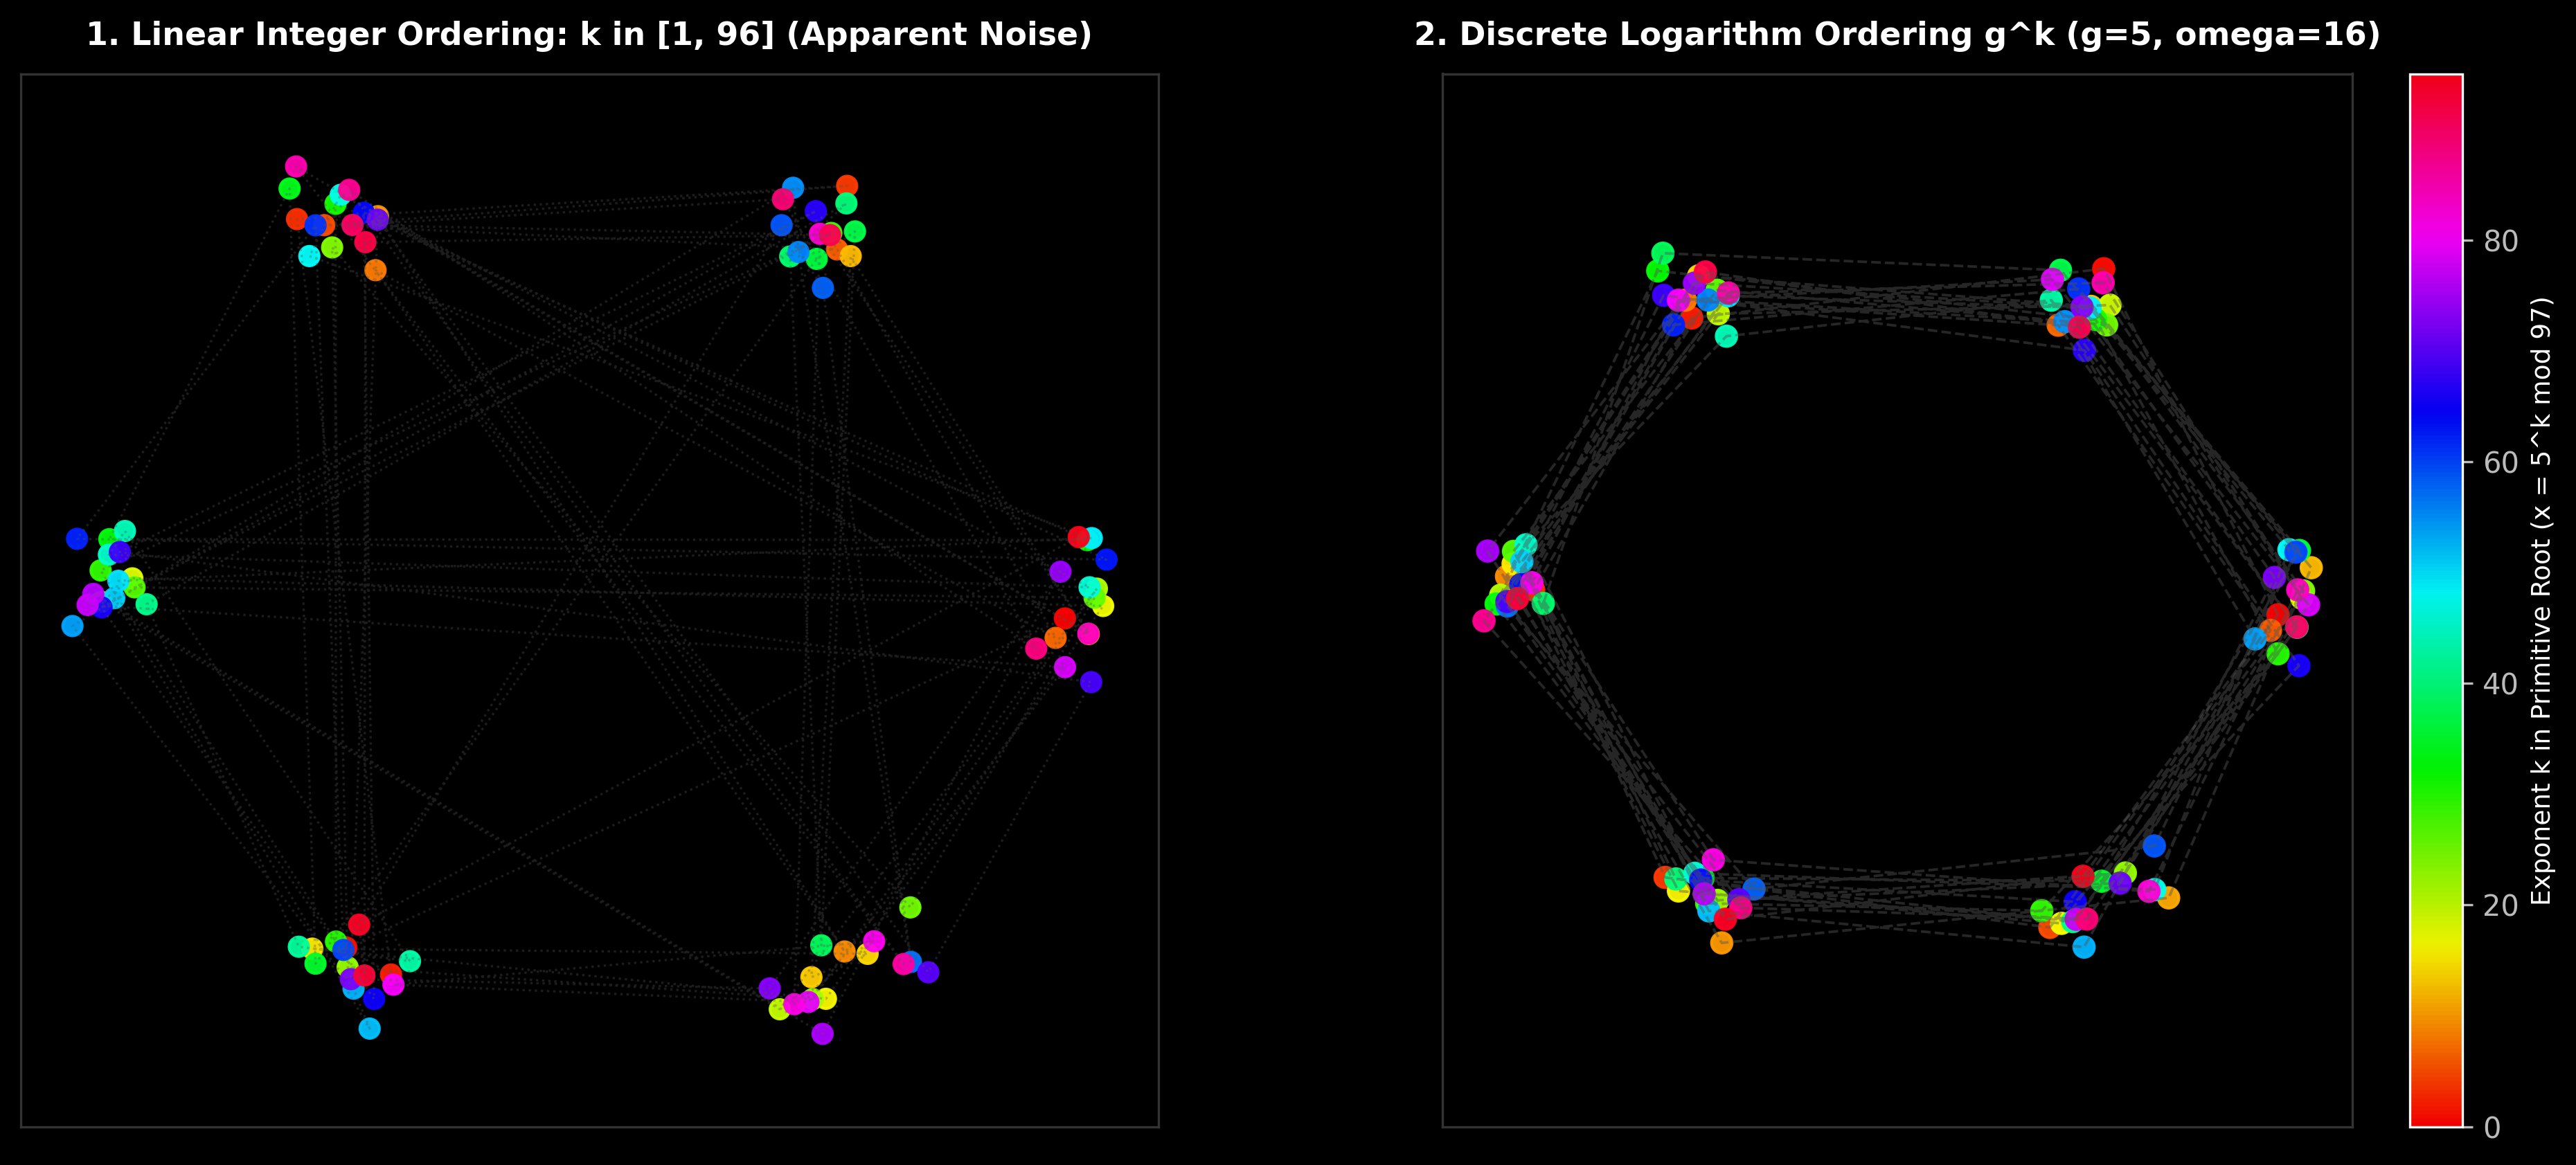

In [8]:
# @title
# =============================================================================
# BLOCK 2: MODULAR MULTIPLICATION (Z_97) - TRAINING & DLOG HEXAGON QUOTIENT
# =============================================================================
P_MUL: int = 97
MAX_STEPS_MUL: int = 2500
WEIGHT_DECAY_MUL: float = 0.1


class PLVFModularMultiplicationModel(nn.Module):
    vocab_size: int = P_MUL + 1
    target_classes: int = P_MUL
    d_model: int = D_MODEL
    d_inter: int = D_INTER
    n_layers: int = N_LAYERS
    m_modes: int = M_MODES
    block_size: int = 3
    dtype: jnp.dtype = DTYPE

    @nn.compact
    def __call__(self, idx: jnp.ndarray) -> Tuple[jnp.ndarray, jnp.ndarray]:
        tok_embed = self.param("token_emb", nn.initializers.normal(stddev=0.02), (self.vocab_size, self.d_model), self.dtype)
        tok_u = to_unit_sphere(tok_embed)
        x = tok_u[idx]

        for i in range(self.n_layers):
            x = PureLieVolterraFlowLayer(
                d_model=self.d_model,
                d_inter=self.d_inter,
                m_modes=self.m_modes,
                block_size=self.block_size,
                dtype=self.dtype,
                name=f"flow_{i}"
            )(x)

        last_state = to_unit_sphere(x[:, -1, :])
        target_vocab_u = tok_u[:self.target_classes, :]
        cos_sim = jnp.matmul(last_state.astype(jnp.float32), target_vocab_u.astype(jnp.float32).T)

        log_tau = self.param("log_tau", lambda rng: jnp.array(math.log(15.0), dtype=jnp.float32))
        tau = jnp.clip(jnp.exp(log_tau), 1.0, 40.0)
        logits = tau * cos_sim
        return logits, tok_u


def get_modular_multiplication_data(seed: int = 42) -> Tuple[jnp.ndarray, jnp.ndarray, jnp.ndarray, jnp.ndarray]:
    rng = np.random.default_rng(seed)
    pairs = [(a, b) for a in range(P_MUL) for b in range(P_MUL)]
    rng.shuffle(pairs)

    n_train = len(pairs) // 2
    train_pairs, val_pairs = pairs[:n_train], pairs[n_train:]

    def build(pair_list):
        x = np.zeros((len(pair_list), 3), dtype=np.int32)
        y = np.zeros((len(pair_list),), dtype=np.int32)
        for i, (a, b) in enumerate(pair_list):
            x[i, 0], x[i, 1], x[i, 2] = a, b, P_MUL
            y[i] = (a * b) % P_MUL
        return jnp.array(x), jnp.array(y)

    x_train, y_train = build(train_pairs)
    x_val, y_val = build(val_pairs)
    return x_train, y_train, x_val, y_val


# -----------------------------------------------------------------------------
# 1. Canonical Training Loop
# -----------------------------------------------------------------------------
x_train_mul, y_train_mul, x_val_mul, y_val_mul = get_modular_multiplication_data(seed=SEED)
model_mul = PLVFModularMultiplicationModel()

init_rng = random.PRNGKey(SEED)
dummy_x = jnp.ones((BATCH_SIZE, 3), dtype=jnp.int32)
params_mul = model_mul.init(init_rng, dummy_x)["params"]

decay_mask_mul = build_decay_mask(params_mul)
tx_mul = optax.chain(
    optax.clip_by_global_norm(1.0),
    optax.adamw(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY_MUL, b1=0.9, b2=0.98, mask=decay_mask_mul)
)
state_mul = train_state.TrainState.create(apply_fn=model_mul.apply, params=params_mul, tx=tx_mul)


@jax.jit
def train_step_mul(state: train_state.TrainState, x: jnp.ndarray, y: jnp.ndarray):
    def loss_fn(p):
        logits, _ = state.apply_fn({"params": p}, x)
        loss = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=y).mean()
        return loss, logits
    (loss, logits), grads = jax.value_and_grad(loss_fn, has_aux=True)(state.params)
    acc = jnp.mean(jnp.argmax(logits, axis=-1) == y)
    return state.apply_gradients(grads=grads), loss, acc


train_rng = random.PRNGKey(SEED)
n_train_mul = len(x_train_mul)

for step in range(1, MAX_STEPS_MUL + 1):
    train_rng, sub_rng = random.split(train_rng)
    idx = random.randint(sub_rng, shape=(BATCH_SIZE,), minval=0, maxval=n_train_mul)
    state_mul, loss_val, acc_val = train_step_mul(state_mul, x_train_mul[idx], y_train_mul[idx])

    if step % 250 == 0:
        val_lg, _ = state_mul.apply_fn({"params": state_mul.params}, x_val_mul)
        val_acc = float(jnp.mean(jnp.argmax(val_lg, axis=-1) == y_val_mul))
        if val_acc >= 0.9999:
            break

_, tok_u_mul = state_mul.apply_fn({"params": state_mul.params}, jnp.ones((1, 3), dtype=jnp.int32))
W_E_mul = np.array(tok_u_mul[:P_MUL], dtype=np.float64)

# -----------------------------------------------------------------------------
# 2. Discrete Logarithm & Z_6 Hexagonal Quotient Analysis
# -----------------------------------------------------------------------------
g_root = 5
dlog_order = [pow(g_root, k, P_MUL) for k in range(P_MUL - 1)]
W_nonzero_dlog = W_E_mul[dlog_order] - np.mean(W_E_mul[dlog_order], axis=0, keepdims=True)
n_units = P_MUL - 1

k_vec_mul = np.arange(n_units)[:, None]
best_fve_mul, best_w_mul, best_proj_mul = 0.0, 1, None
total_var_mul = np.sum(W_nonzero_dlog**2)

for w in range(1, n_units // 2):
    cb = np.sqrt(2.0 / n_units) * np.cos(2.0 * np.pi * w * k_vec_mul / n_units)
    sb = np.sqrt(2.0 / n_units) * np.sin(2.0 * np.pi * w * k_vec_mul / n_units)
    px = W_nonzero_dlog @ (cb.T @ W_nonzero_dlog).T
    py = W_nonzero_dlog @ (sb.T @ W_nonzero_dlog).T
    fve = (np.sum(px**2) + np.sum(py**2)) / total_var_mul
    if fve > best_fve_mul:
        best_fve_mul = fve
        best_w_mul = w
        best_proj_mul = np.hstack([px, py])

pts_by_int = np.zeros_like(best_proj_mul)
for k_exp, val in enumerate(dlog_order):
    pts_by_int[val - 1] = best_proj_mul[k_exp]

fig_mul, axes_mul = plt.subplots(1, 2, figsize=(14, 6.5), facecolor="#000000", dpi=300)
fig_mul.subplots_adjust(wspace=0.25, left=0.06, right=0.94, top=0.88, bottom=0.10)

ax1 = axes_mul[0]
ax1.set_facecolor("#000000")
ax1.plot(pts_by_int[:, 0], pts_by_int[:, 1], color="#555555", alpha=0.35, linestyle=":", linewidth=0.8)
ax1.scatter(pts_by_int[:, 0], pts_by_int[:, 1], c=np.arange(1, P_MUL), cmap=plt.cm.hsv, s=45, alpha=0.95)
ax1.set_title("1. Linear Integer Ordering: k in [1, 96] (Apparent Noise)", fontsize=11, fontweight="bold", pad=10)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_aspect("equal", adjustable="datalim")
for spine in ax1.spines.values():
    spine.set_color("#333333")

ax2 = axes_mul[1]
ax2.set_facecolor("#000000")
ax2.plot(best_proj_mul[:, 0], best_proj_mul[:, 1], color="#555555", alpha=0.45, linestyle="--", linewidth=0.9)
ax2.plot([best_proj_mul[-1, 0], best_proj_mul[0, 0]], [best_proj_mul[-1, 1], best_proj_mul[0, 1]], color="#555555", alpha=0.45, linestyle="--", linewidth=0.9)
scatter_mul = ax2.scatter(best_proj_mul[:, 0], best_proj_mul[:, 1], c=np.arange(n_units), cmap=plt.cm.hsv, s=50, alpha=0.95)
ax2.set_title(f"2. Discrete Logarithm Ordering g^k (g=5, omega={best_w_mul})", fontsize=11, fontweight="bold", pad=10)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_aspect("equal", adjustable="datalim")
for spine in ax2.spines.values():
    spine.set_color("#333333")

cbar_mul = plt.colorbar(scatter_mul, ax=ax2)
cbar_mul.set_label("Exponent k in Primitive Root (x = 5^k mod 97)", fontsize=9)

plt.show()

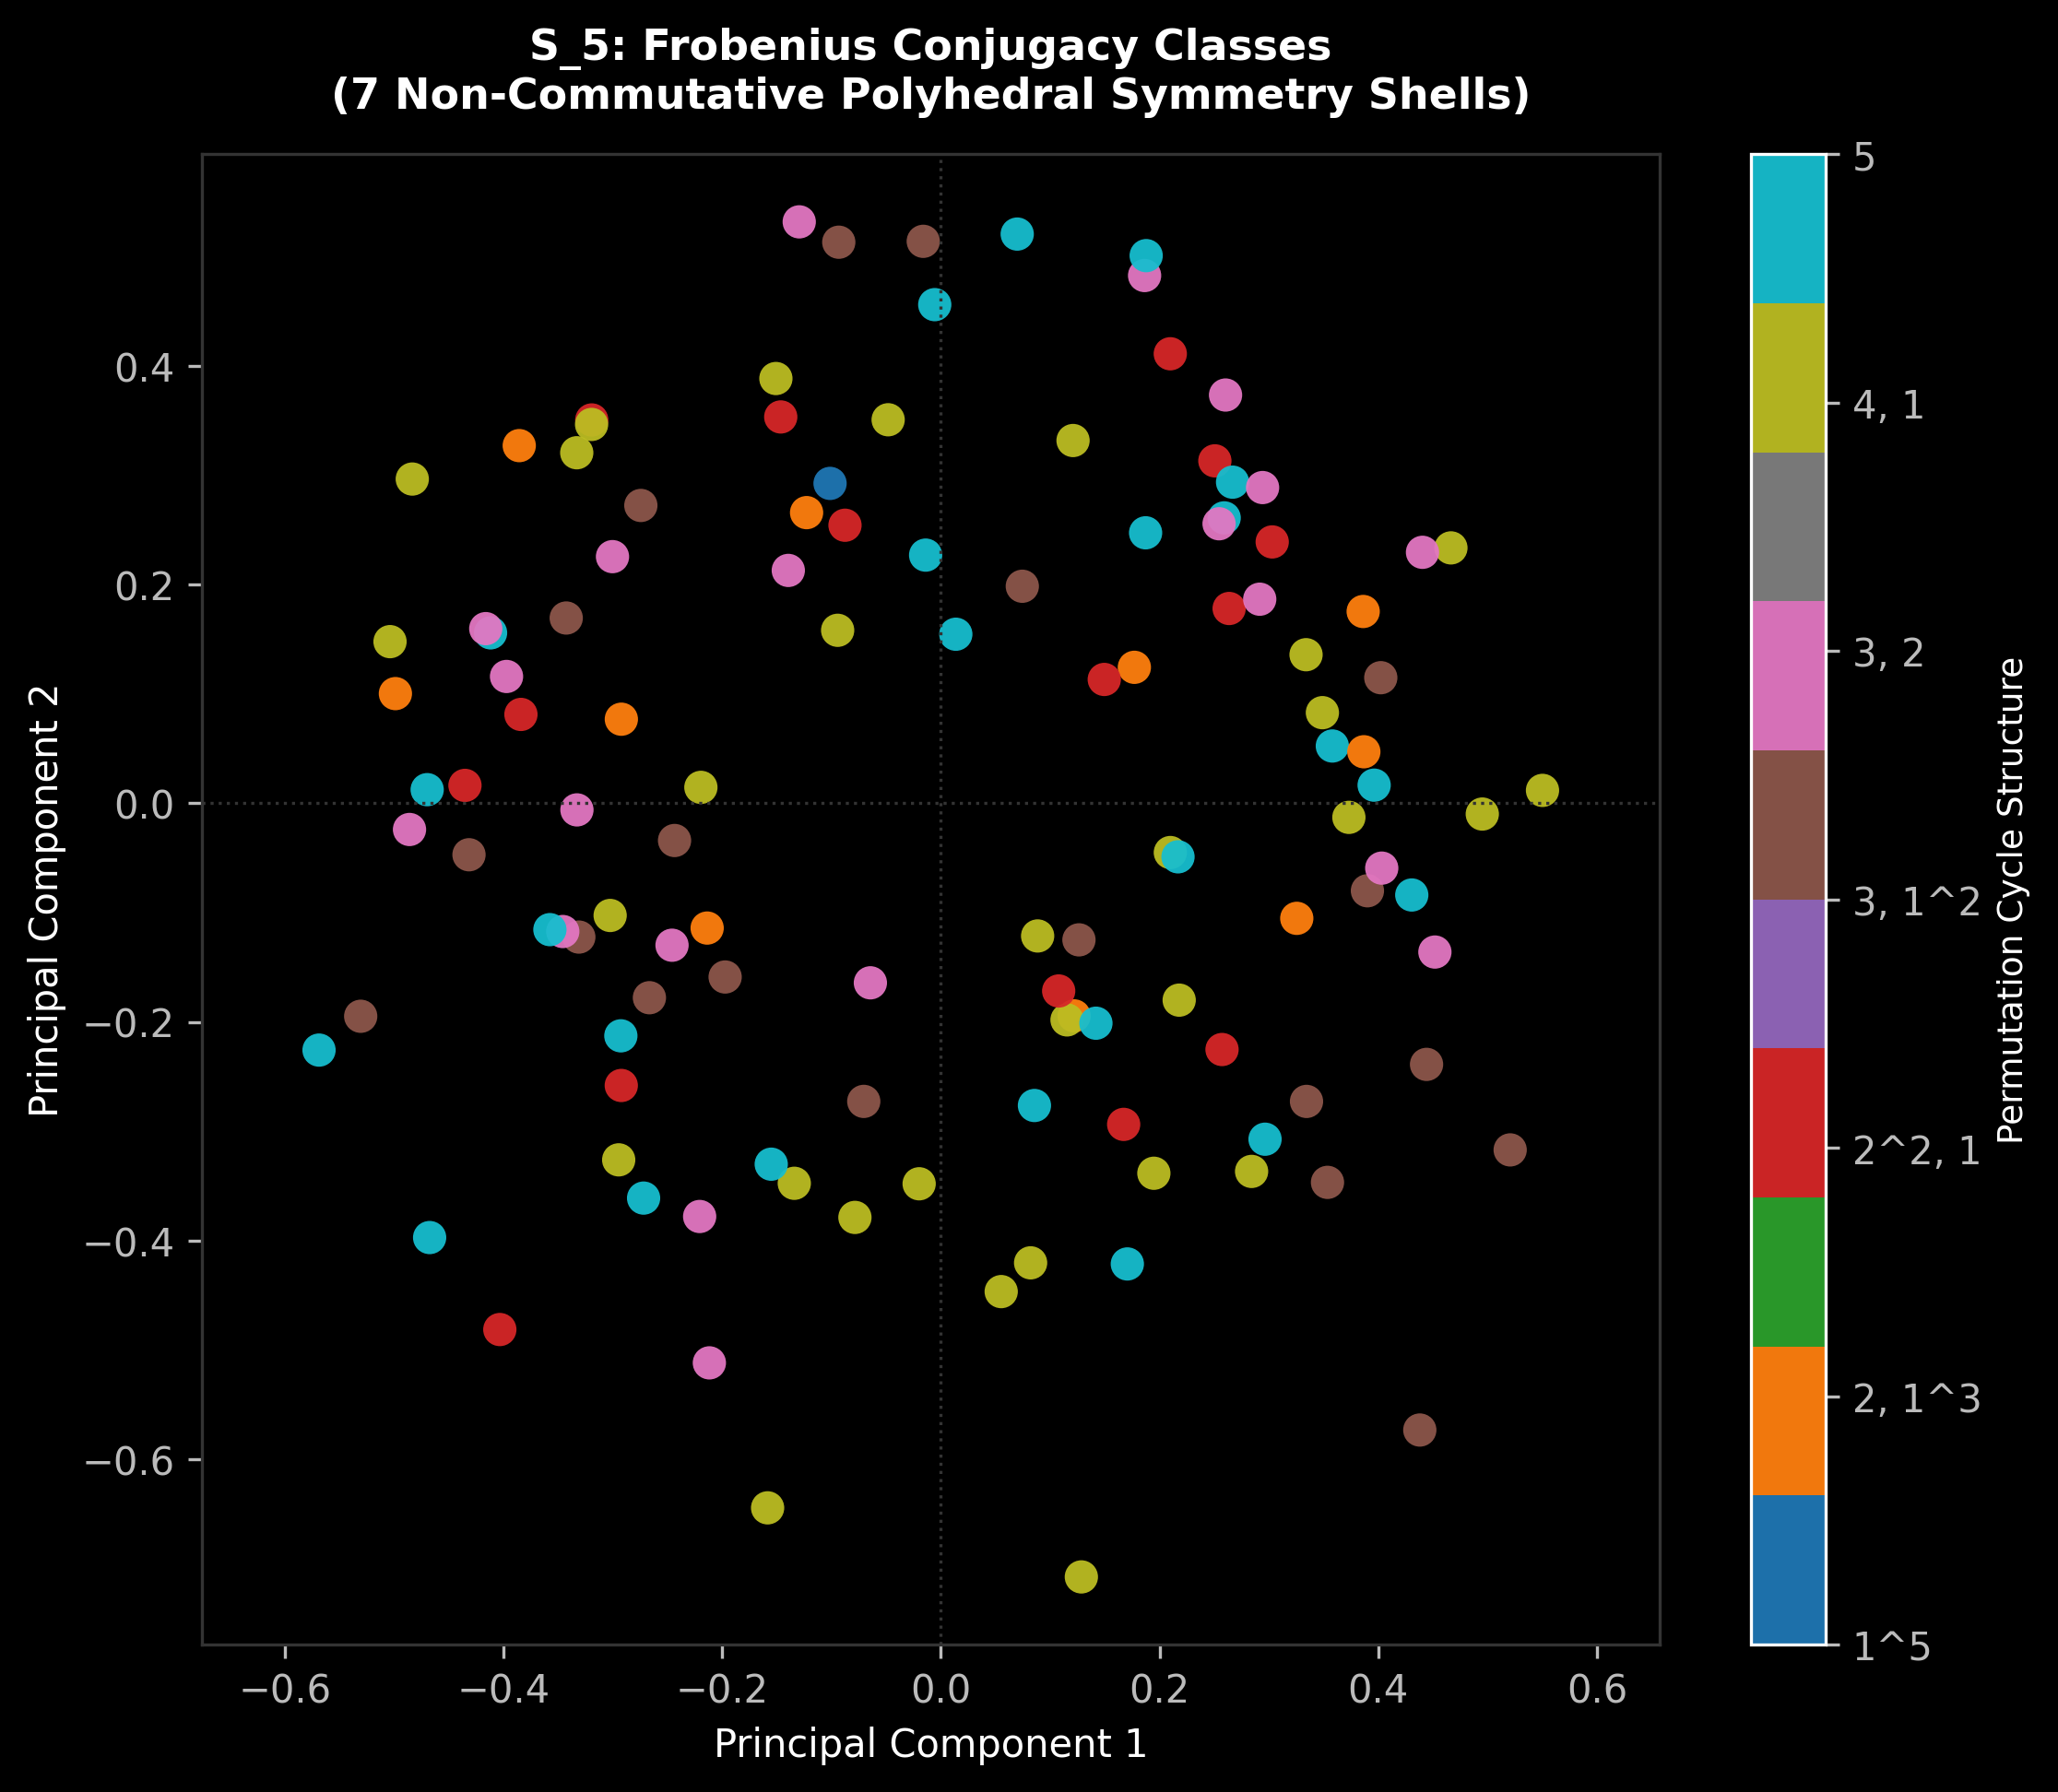

In [9]:
# @title
# =============================================================================
# BLOCK 3: PERMUTATIONS S_5 - TRAINING & FROBENIUS CONJUGACY CLASSES
# =============================================================================
import itertools
from sklearn.decomposition import PCA

N_PERMS: int = 120
MAX_STEPS_S5: int = 15000
WEIGHT_DECAY_S5: float = 1.0


class PLVFS5Model(nn.Module):
    vocab_size: int = N_PERMS + 1
    target_classes: int = N_PERMS
    d_model: int = D_MODEL
    d_inter: int = D_INTER
    n_layers: int = N_LAYERS
    m_modes: int = M_MODES
    block_size: int = 3
    dtype: jnp.dtype = DTYPE

    @nn.compact
    def __call__(self, idx: jnp.ndarray) -> Tuple[jnp.ndarray, jnp.ndarray]:
        tok_embed = self.param("token_emb", nn.initializers.normal(stddev=0.02), (self.vocab_size, self.d_model), self.dtype)
        tok_u = to_unit_sphere(tok_embed)
        x = tok_u[idx]

        for i in range(self.n_layers):
            x = PureLieVolterraFlowLayer(
                d_model=self.d_model,
                d_inter=self.d_inter,
                m_modes=self.m_modes,
                block_size=self.block_size,
                dtype=self.dtype,
                name=f"flow_{i}"
            )(x)

        last_state = to_unit_sphere(x[:, -1, :])
        target_vocab_u = tok_u[:self.target_classes, :]
        cos_sim = jnp.matmul(last_state.astype(jnp.float32), target_vocab_u.astype(jnp.float32).T)

        log_tau = self.param("log_tau", lambda rng: jnp.array(math.log(18.0), dtype=jnp.float32))
        tau = jnp.clip(jnp.exp(log_tau), 2.5, 30.0)
        logits = tau * cos_sim
        return logits, tok_u


perms_s5 = list(itertools.permutations(range(5)))
perm_to_idx_s5 = {p: i for i, p in enumerate(perms_s5)}


def get_cycle_type_s5(p):
    visited = [False] * 5
    cycles = []
    for i in range(5):
        if not visited[i]:
            c_len = 0
            curr = i
            while not visited[curr]:
                visited[curr] = True
                curr = p[curr]
                c_len += 1
            cycles.append(c_len)
    return tuple(sorted(cycles, reverse=True))


cycle_types_unique_s5 = [
    (1, 1, 1, 1, 1),
    (2, 1, 1, 1),
    (2, 2, 1),
    (3, 1, 1),
    (3, 2),
    (4, 1),
    (5,)
]
cycle_type_map_s5 = {ct: i for i, ct in enumerate(cycle_types_unique_s5)}
perm_labels_cycle_s5 = np.array([cycle_type_map_s5[get_cycle_type_s5(p)] for p in perms_s5])


def get_s5_permutation_data(seed: int = 42) -> Tuple[jnp.ndarray, jnp.ndarray, jnp.ndarray, jnp.ndarray]:
    rng = np.random.default_rng(seed)
    pairs = [(i, j) for i in range(N_PERMS) for j in range(N_PERMS)]
    rng.shuffle(pairs)

    n_train = len(pairs) // 2
    train_pairs, val_pairs = pairs[:n_train], pairs[n_train:]

    def build(pair_list):
        x = np.zeros((len(pair_list), 3), dtype=np.int32)
        y = np.zeros((len(pair_list),), dtype=np.int32)
        for idx, (i, j) in enumerate(pair_list):
            p1, p2 = perms_s5[i], perms_s5[j]
            comp = tuple(p1[p2[k]] for k in range(5))
            x[idx, 0], x[idx, 1], x[idx, 2] = i, j, N_PERMS
            y[idx] = perm_to_idx_s5[comp]
        return jnp.array(x), jnp.array(y)

    x_train, y_train = build(train_pairs)
    x_val, y_val = build(val_pairs)
    return x_train, y_train, x_val, y_val


# -----------------------------------------------------------------------------
# 1. Canonical Training Loop
# -----------------------------------------------------------------------------
x_train_s5, y_train_s5, x_val_s5, y_val_s5 = get_s5_permutation_data(seed=SEED)
model_s5 = PLVFS5Model()

init_rng = random.PRNGKey(SEED)
dummy_x = jnp.ones((BATCH_SIZE, 3), dtype=jnp.int32)
params_s5 = model_s5.init(init_rng, dummy_x)["params"]

tx_s5 = optax.chain(
    optax.clip_by_global_norm(1.0),
    optax.adamw(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY_S5, b1=0.9, b2=0.98)
)
state_s5 = train_state.TrainState.create(apply_fn=model_s5.apply, params=params_s5, tx=tx_s5)


@jax.jit
def train_step_s5(state: train_state.TrainState, x: jnp.ndarray, y: jnp.ndarray):
    def loss_fn(p):
        logits, _ = state.apply_fn({"params": p}, x)
        loss = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=y).mean()
        return loss, logits
    (loss, logits), grads = jax.value_and_grad(loss_fn, has_aux=True)(state.params)
    acc = jnp.mean(jnp.argmax(logits, axis=-1) == y)
    return state.apply_gradients(grads=grads), loss, acc


train_rng = random.PRNGKey(SEED)
n_train_s5 = len(x_train_s5)

for step in range(1, MAX_STEPS_S5 + 1):
    train_rng, sub_rng = random.split(train_rng)
    idx = random.randint(sub_rng, shape=(BATCH_SIZE,), minval=0, maxval=n_train_s5)
    state_s5, loss_val, acc_val = train_step_s5(state_s5, x_train_s5[idx], y_train_s5[idx])

    if step % 500 == 0:
        val_lg, _ = state_s5.apply_fn({"params": state_s5.params}, x_val_s5)
        val_acc = float(jnp.mean(jnp.argmax(val_lg, axis=-1) == y_val_s5))
        if val_acc >= 0.9999:
            break

_, tok_u_s5 = state_s5.apply_fn({"params": state_s5.params}, jnp.ones((1, 3), dtype=jnp.int32))
W_E_s5 = np.array(tok_u_s5[:N_PERMS], dtype=np.float64)

# -----------------------------------------------------------------------------
# 2. Frobenius Conjugacy Class PCA Projection
# -----------------------------------------------------------------------------
pca_s5 = PCA(n_components=2)
s5_2d = pca_s5.fit_transform(W_E_s5)

fig_s5, ax_s5 = plt.subplots(figsize=(8.5, 7.0), facecolor="#000000", dpi=300)
ax_s5.set_facecolor("#000000")

scatter_s5 = ax_s5.scatter(
    s5_2d[:, 0], s5_2d[:, 1],
    c=perm_labels_cycle_s5,
    cmap=plt.cm.tab10,
    s=75, alpha=0.95, edgecolors="none"
)

ax_s5.set_title("S_5: Frobenius Conjugacy Classes\n(7 Non-Commutative Polyhedral Symmetry Shells)", fontsize=11, fontweight="bold", pad=12)
ax_s5.set_xlabel("Principal Component 1", fontsize=10)
ax_s5.set_ylabel("Principal Component 2", fontsize=10)
ax_s5.axhline(0, color="#333333", linestyle=":", linewidth=0.8)
ax_s5.axvline(0, color="#333333", linestyle=":", linewidth=0.8)
ax_s5.set_aspect("equal", adjustable="datalim")

for spine in ax_s5.spines.values():
    spine.set_color("#333333")

cbar_s5 = plt.colorbar(scatter_s5, ax=ax_s5, ticks=range(7))
cbar_s5.set_ticklabels(["1^5", "2, 1^3", "2^2, 1", "3, 1^2", "3, 2", "4, 1", "5"])
cbar_s5.set_label("Permutation Cycle Structure", fontsize=9)

plt.show()

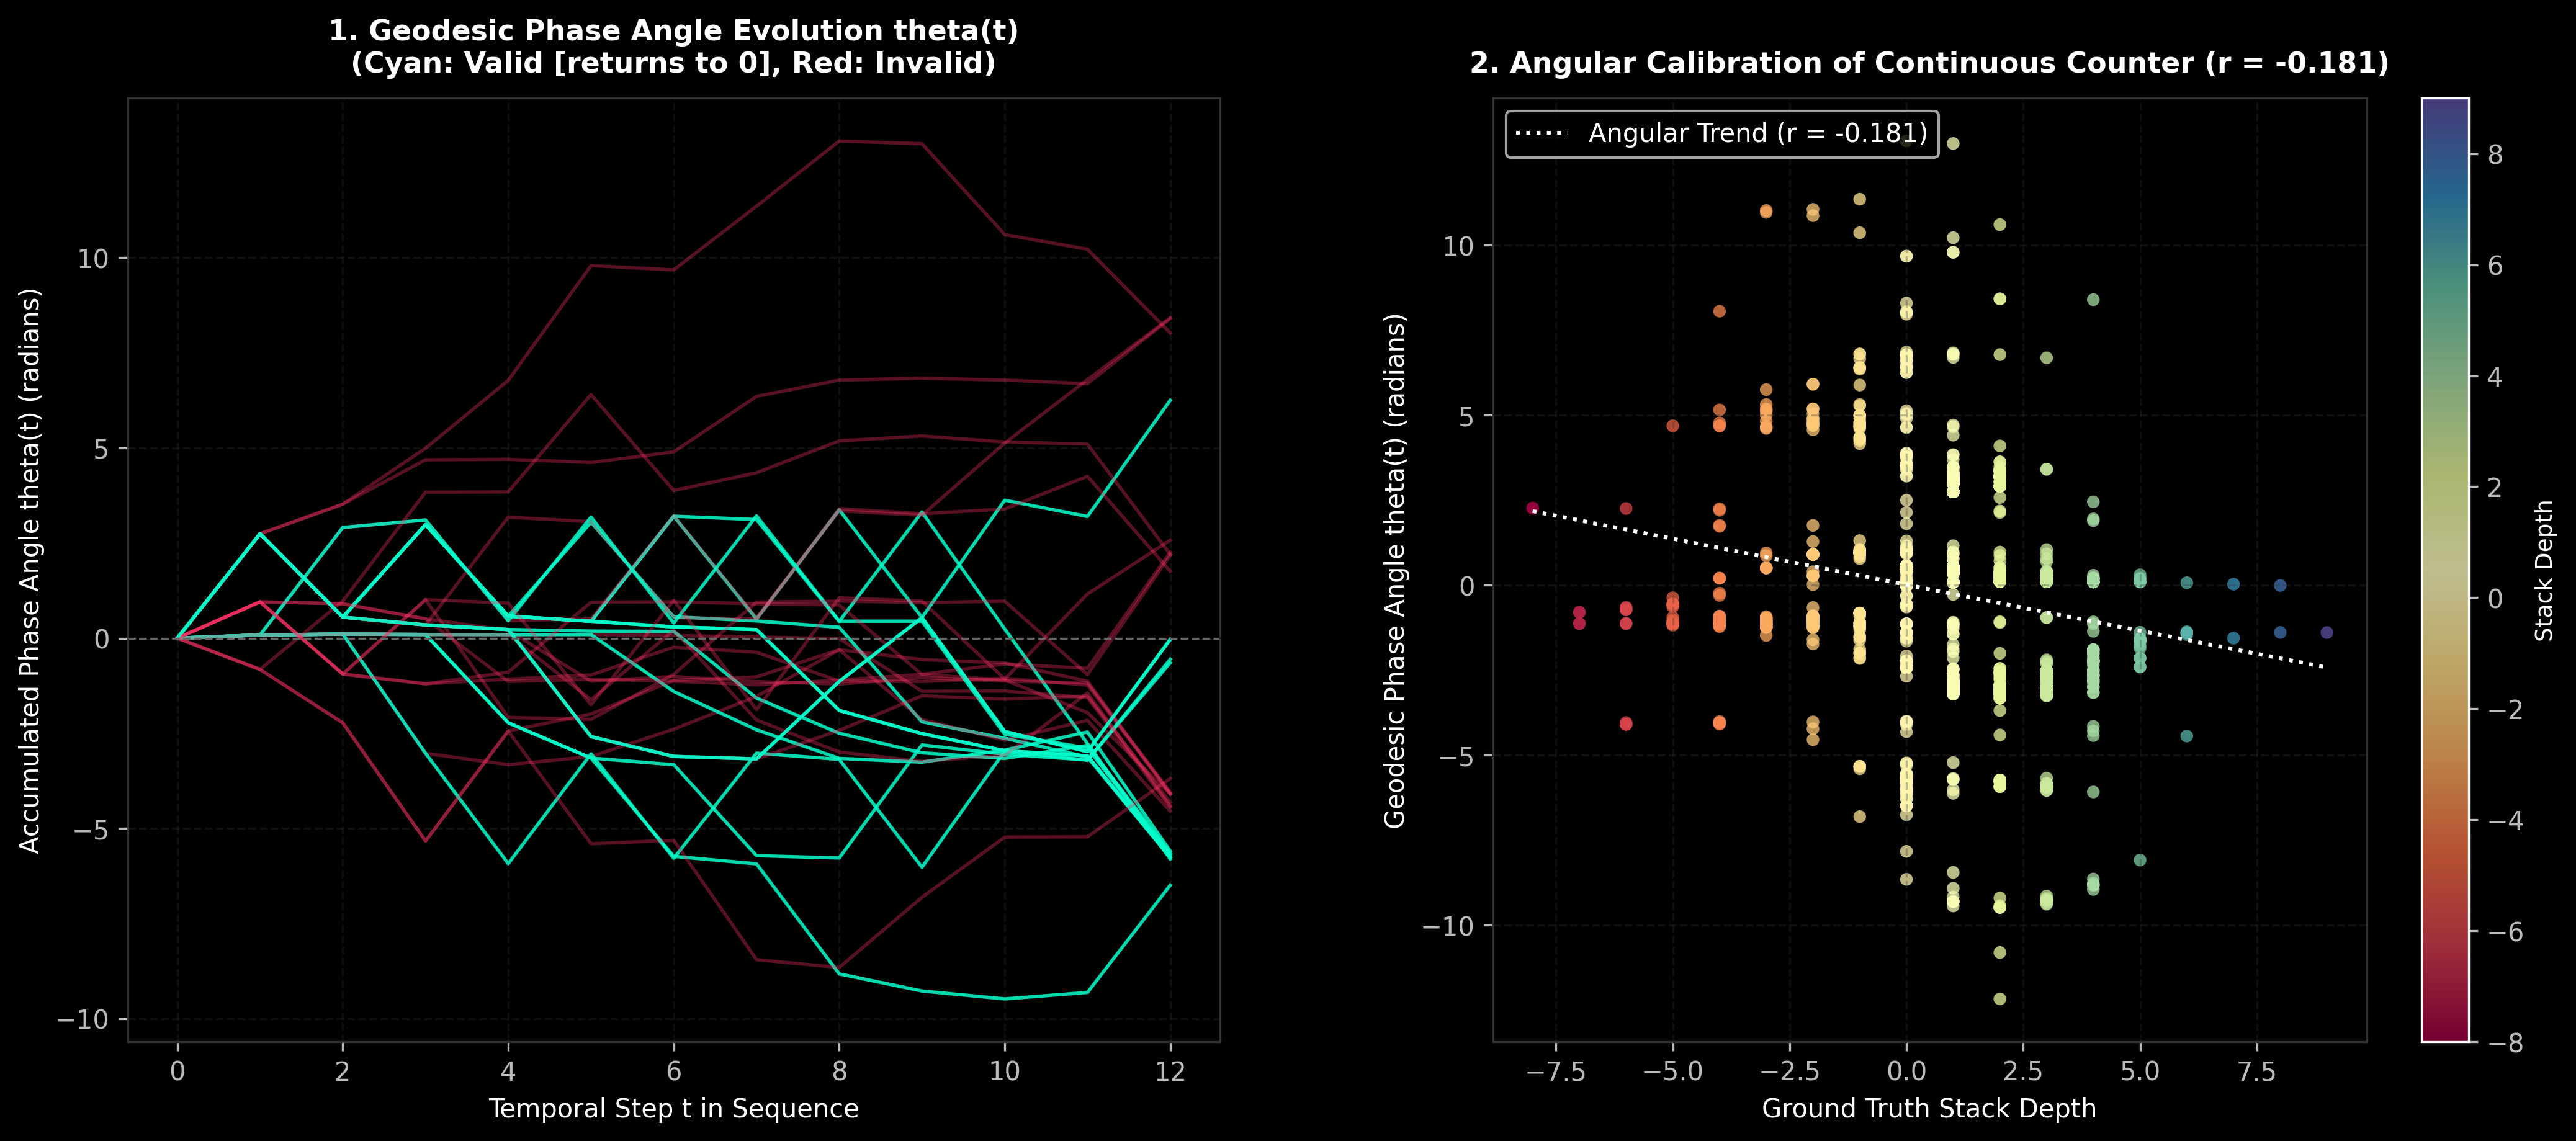

In [10]:
# @title
# =============================================================================
# BLOCK 4: FORMAL LANGUAGE DYCK-1 - TRAINING & POLAR WINDING COUNTER
# =============================================================================
from sklearn.decomposition import PCA

SEQ_LEN_DYCK: int = 12
VOCAB_SIZE_DYCK: int = 4
BLOCK_SIZE_DYCK: int = SEQ_LEN_DYCK + 1
MAX_STEPS_DYCK: int = 2500
WEIGHT_DECAY_DYCK: float = 0.05


class PLVFDyckModel(nn.Module):
    vocab_size: int = VOCAB_SIZE_DYCK
    n_classes: int = 2
    d_model: int = D_MODEL
    d_inter: int = D_INTER
    n_layers: int = N_LAYERS
    m_modes: int = M_MODES
    block_size: int = BLOCK_SIZE_DYCK
    dtype: jnp.dtype = DTYPE

    @nn.compact
    def __call__(self, idx: jnp.ndarray, return_trajectory: bool = False) -> Any:
        tok_embed = self.param("token_emb", nn.initializers.normal(stddev=0.02), (self.vocab_size, self.d_model), self.dtype)
        tok_u = to_unit_sphere(tok_embed)
        x = tok_u[idx]

        for i in range(self.n_layers):
            x = PureLieVolterraFlowLayer(
                d_model=self.d_model,
                d_inter=self.d_inter,
                m_modes=self.m_modes,
                block_size=self.block_size,
                dtype=self.dtype,
                name=f"flow_{i}"
            )(x)

        last_state = to_unit_sphere(x[:, -1, :])
        w_classes = self.param("w_classes", nn.initializers.normal(stddev=0.02), (self.n_classes, self.d_model), self.dtype)
        cos_sim = jnp.matmul(last_state.astype(jnp.float32), to_unit_sphere(w_classes).astype(jnp.float32).T)

        log_tau = self.param("log_tau", lambda rng: jnp.array(math.log(15.0), dtype=jnp.float32))
        tau = jnp.clip(jnp.exp(log_tau), 1.0, 40.0)
        logits = tau * cos_sim

        if return_trajectory:
            return logits, x
        return logits


def get_dyck1_data(n_samples: int = 8000, seed: int = 42) -> Tuple[jnp.ndarray, jnp.ndarray, jnp.ndarray, jnp.ndarray]:
    rng = np.random.default_rng(seed)
    half = n_samples // 2
    samples, labels = [], []

    def generate_balanced(length):
        res = []
        depth = 0
        for step in range(length):
            rem = length - step
            if depth == 0:
                res.append(0)
                depth += 1
            elif depth == rem:
                res.append(1)
                depth -= 1
            else:
                choice = rng.choice([0, 1])
                res.append(choice)
                depth += 1 if choice == 0 else -1
        return res

    for _ in range(half):
        samples.append(generate_balanced(SEQ_LEN_DYCK))
        labels.append(1)

    for _ in range(half):
        cand = rng.integers(0, 2, size=SEQ_LEN_DYCK).tolist()
        d = 0
        is_bal = True
        for b in cand:
            d += 1 if b == 0 else -1
            if d < 0:
                is_bal = False
                break
        if d != 0:
            is_bal = False
        samples.append(cand)
        labels.append(1 if is_bal else 0)

    indices = np.arange(n_samples)
    rng.shuffle(indices)

    x_all = np.zeros((n_samples, BLOCK_SIZE_DYCK), dtype=np.int32)
    y_all = np.array([labels[i] for i in indices], dtype=np.int32)

    for idx, sample_idx in enumerate(indices):
        x_all[idx, :SEQ_LEN_DYCK] = samples[sample_idx]
        x_all[idx, SEQ_LEN_DYCK] = 2

    split = int(0.7 * n_samples)
    x_train, y_train = jnp.array(x_all[:split]), jnp.array(y_all[:split])
    x_val, y_val = jnp.array(x_all[split:]), jnp.array(y_all[split:])
    return x_train, y_train, x_val, y_val


# -----------------------------------------------------------------------------
# 1. Canonical Training Loop
# -----------------------------------------------------------------------------
x_train_dyck, y_train_dyck, x_val_dyck, y_val_dyck = get_dyck1_data(seed=SEED)
model_dyck = PLVFDyckModel()

init_rng = random.PRNGKey(SEED)
dummy_x = jnp.ones((BATCH_SIZE, BLOCK_SIZE_DYCK), dtype=jnp.int32)
params_dyck = model_dyck.init(init_rng, dummy_x)["params"]

decay_mask_dyck = build_decay_mask(params_dyck)
tx_dyck = optax.chain(
    optax.clip_by_global_norm(1.0),
    optax.adamw(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY_DYCK, b1=0.9, b2=0.98, mask=decay_mask_dyck)
)
state_dyck = train_state.TrainState.create(apply_fn=model_dyck.apply, params=params_dyck, tx=tx_dyck)


@jax.jit
def train_step_dyck(state: train_state.TrainState, x: jnp.ndarray, y: jnp.ndarray):
    def loss_fn(p):
        logits = state.apply_fn({"params": p}, x)
        loss = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=y).mean()
        return loss, logits
    (loss, logits), grads = jax.value_and_grad(loss_fn, has_aux=True)(state.params)
    acc = jnp.mean(jnp.argmax(logits, axis=-1) == y)
    return state.apply_gradients(grads=grads), loss, acc


train_rng = random.PRNGKey(SEED)
n_train_dyck = len(x_train_dyck)

for step in range(1, MAX_STEPS_DYCK + 1):
    train_rng, sub_rng = random.split(train_rng)
    idx = random.randint(sub_rng, shape=(BATCH_SIZE,), minval=0, maxval=n_train_dyck)
    state_dyck, loss_val, acc_val = train_step_dyck(state_dyck, x_train_dyck[idx], y_train_dyck[idx])

    if step % 250 == 0:
        val_lg = state_dyck.apply_fn({"params": state_dyck.params}, x_val_dyck)
        val_acc = float(jnp.mean(jnp.argmax(val_lg, axis=-1) == y_val_dyck))
        if val_acc >= 0.9999:
            break

# -----------------------------------------------------------------------------
# 2. Continuous Polar Winding & Phase Evolution
# -----------------------------------------------------------------------------
sample_x_dyck = x_val_dyck[:100]
sample_y_dyck = y_val_dyck[:100]
_, trajs_dyck = state_dyck.apply_fn({"params": state_dyck.params}, sample_x_dyck, return_trajectory=True)
trajs_dyck = np.array(trajs_dyck, dtype=np.float32)

flat_states_dyck = trajs_dyck.reshape(-1, D_MODEL)
pca_dyck = PCA(n_components=2)
flat_2d_dyck = pca_dyck.fit_transform(flat_states_dyck)
trajs_2d_dyck = flat_2d_dyck.reshape(len(sample_x_dyck), BLOCK_SIZE_DYCK, 2)

angles_unwrapped_dyck = []
theoretical_depths_dyck = []

for i in range(len(sample_x_dyck)):
    raw_theta = np.arctan2(trajs_2d_dyck[i, :, 1], trajs_2d_dyck[i, :, 0])
    unwrapped = np.unwrap(raw_theta)
    angles_unwrapped_dyck.append(unwrapped - unwrapped[0])

    d = 0
    d_seq = [0]
    for tok in sample_x_dyck[i][:SEQ_LEN_DYCK]:
        d += (1 if tok == 0 else -1)
        d_seq.append(d)
    theoretical_depths_dyck.append(d_seq)

angles_arr_dyck = np.array(angles_unwrapped_dyck)
depths_arr_dyck = np.array(theoretical_depths_dyck)
corr_phase_dyck = np.corrcoef(angles_arr_dyck.flatten(), depths_arr_dyck.flatten())[0, 1]

fig_dyck, axes_dyck = plt.subplots(1, 2, figsize=(15, 6.5), facecolor="#000000", dpi=300)
fig_dyck.subplots_adjust(wspace=0.25, left=0.06, right=0.94, top=0.88, bottom=0.10)

ax1 = axes_dyck[0]
ax1.set_facecolor("#000000")
steps_dyck = np.arange(BLOCK_SIZE_DYCK)
for i in range(30):
    color = "#00ffcc" if sample_y_dyck[i] == 1 else "#ff3366"
    alpha = 0.85 if sample_y_dyck[i] == 1 else 0.35
    ax1.plot(steps_dyck, angles_arr_dyck[i], color=color, alpha=alpha, linewidth=1.3)

ax1.axhline(0, color="#666666", linestyle="--", linewidth=0.8)
ax1.set_title("1. Geodesic Phase Angle Evolution theta(t)\n(Cyan: Valid [returns to 0], Red: Invalid)", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("Temporal Step t in Sequence", fontsize=10)
ax1.set_ylabel("Accumulated Phase Angle theta(t) (radians)", fontsize=10)
for spine in ax1.spines.values():
    spine.set_color("#333333")
ax1.grid(True, linestyle="--", alpha=0.3)

ax2 = axes_dyck[1]
ax2.set_facecolor("#000000")
scatter_dyck = ax2.scatter(depths_arr_dyck.flatten(), angles_arr_dyck.flatten(), c=depths_arr_dyck.flatten(), cmap=plt.cm.Spectral, s=24, alpha=0.75, edgecolors="none")

slope_dyck, intercept_dyck = np.polyfit(depths_arr_dyck.flatten(), angles_arr_dyck.flatten(), 1)
d_range_dyck = np.linspace(np.min(depths_arr_dyck), np.max(depths_arr_dyck), 100)
ax2.plot(d_range_dyck, slope_dyck * d_range_dyck + intercept_dyck, color="#ffffff", linestyle=":", linewidth=1.5, label=f"Angular Trend (r = {corr_phase_dyck:.3f})")

ax2.set_title(f"2. Angular Calibration of Continuous Counter (r = {corr_phase_dyck:.3f})", fontsize=11, fontweight="bold", pad=10)
ax2.set_xlabel("Ground Truth Stack Depth", fontsize=10)
ax2.set_ylabel("Geodesic Phase Angle theta(t) (radians)", fontsize=10)
ax2.legend(loc="upper left")
for spine in ax2.spines.values():
    spine.set_color("#333333")
ax2.grid(True, linestyle="--", alpha=0.3)

cbar_dyck = plt.colorbar(scatter_dyck, ax=ax2)
cbar_dyck.set_label("Stack Depth", fontsize=9)

plt.show()

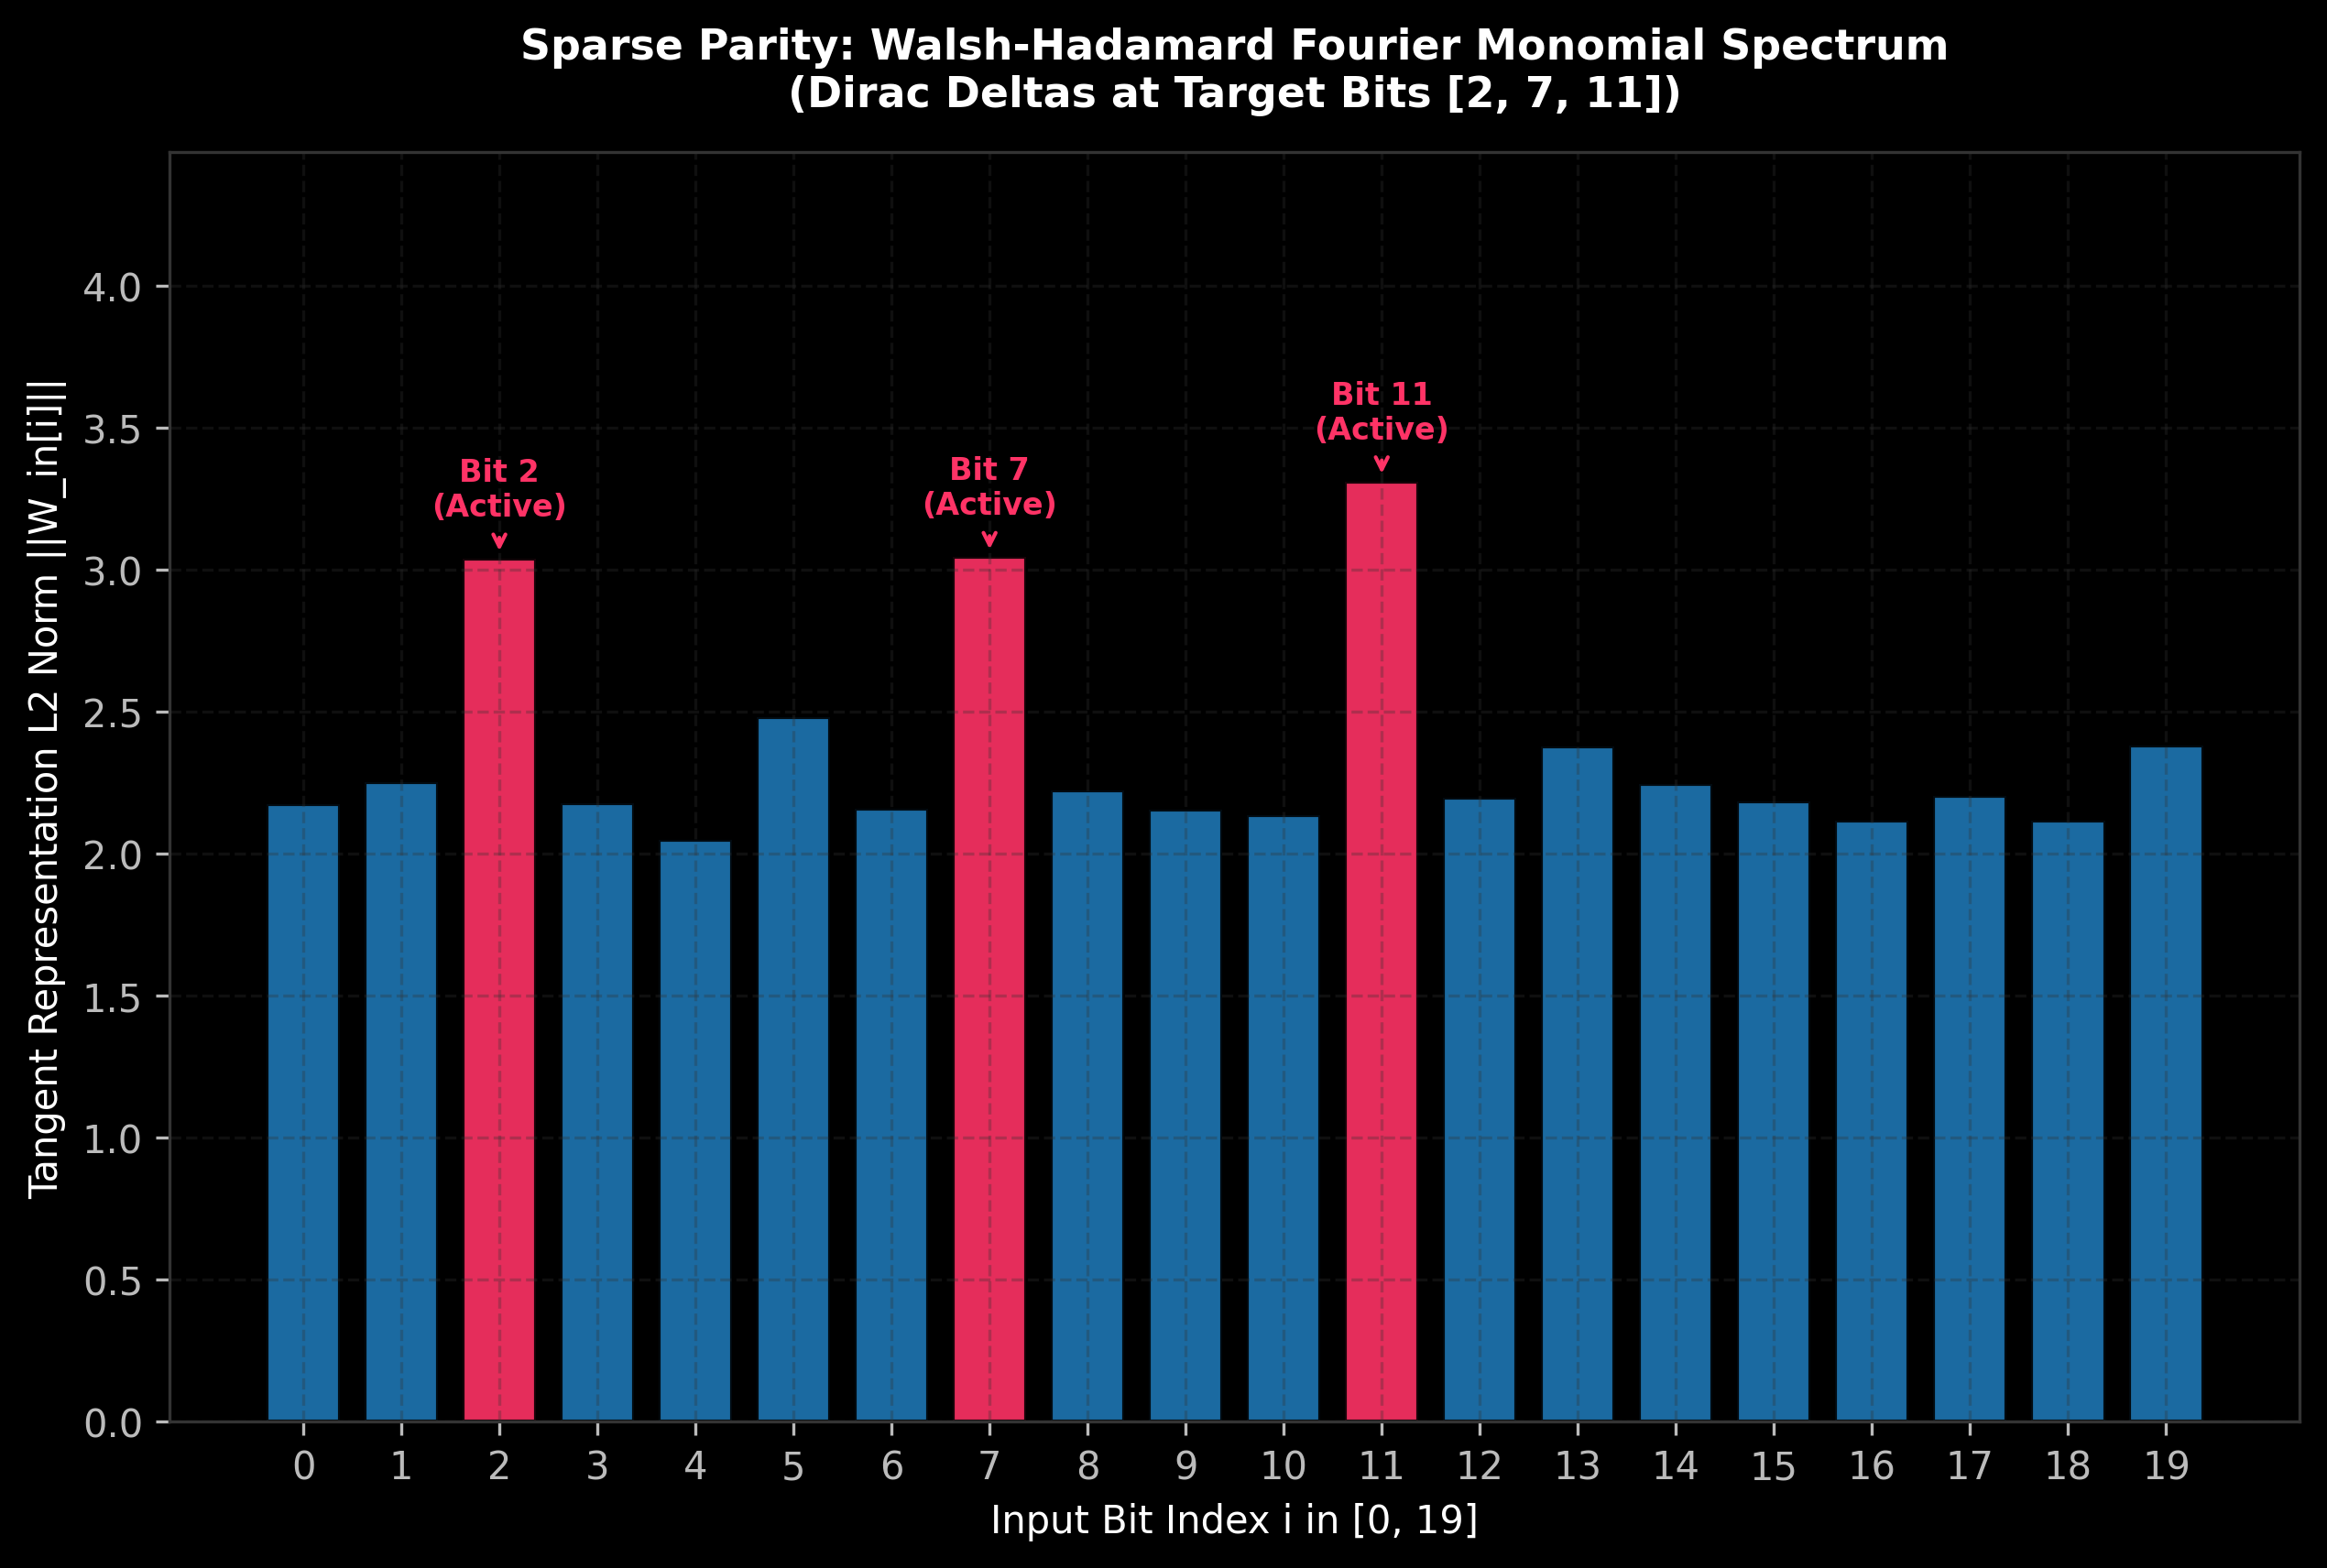

In [11]:
# @title
# =============================================================================
# BLOCK 5: DENSE SPARSE PARITY - TRAINING & WALSH-HADAMARD DELTA SPECTRUM
# =============================================================================
N_BITS_PARITY: int = 20
K_RELEVANT_PARITY: int = 3
TARGET_INDICES_PARITY: List[int] = [2, 7, 11]

N_TRAIN_PARITY: int = 12000
N_VAL_PARITY: int = 4000
MAX_STEPS_PARITY: int = 2500
WEIGHT_DECAY_PARITY: float = 0.01


class LieSphericalParityLayer(nn.Module):
    d_model: int = D_MODEL
    d_inter: int = D_INTER
    dtype: jnp.dtype = DTYPE

    @nn.compact
    def __call__(self, x: jnp.ndarray) -> jnp.ndarray:
        w_u = nn.Dense(self.d_inter, use_bias=False, dtype=self.dtype, name="w_u")
        w_v = nn.Dense(self.d_inter, use_bias=False, dtype=self.dtype, name="w_v")
        w_proj = nn.Dense(self.d_model, use_bias=False, dtype=self.dtype, name="w_proj")

        u = nn.silu(w_u(x))
        v = nn.silu(w_v(x))
        force = w_proj(u * v)

        v_tangent = lie_bivector_action(force, force * 0.5 + x, x)
        eta = self.param("tangent_scale", lambda rng: jnp.array(0.10, dtype=jnp.float32))
        return unit_riemannian_expmap(x, v_tangent * eta)


class PLVFSparseParityModel(nn.Module):
    n_bits: int = N_BITS_PARITY
    n_classes: int = 2
    d_model: int = D_MODEL
    d_inter: int = D_INTER
    n_layers: int = N_LAYERS
    dtype: jnp.dtype = DTYPE

    @nn.compact
    def __call__(self, x: jnp.ndarray) -> Tuple[jnp.ndarray, jnp.ndarray]:
        w_in = nn.Dense(self.d_model, use_bias=False, dtype=self.dtype, name="w_in")
        x_sphere = to_unit_sphere(w_in(x))

        for i in range(self.n_layers):
            x_sphere = LieSphericalParityLayer(
                d_model=self.d_model,
                d_inter=self.d_inter,
                dtype=self.dtype,
                name=f"flow_{i}"
            )(x_sphere)

        w_classes = self.param("w_classes", nn.initializers.normal(stddev=0.02), (self.n_classes, self.d_model), self.dtype)
        w_classes_u = to_unit_sphere(w_classes)
        cos_sim = jnp.matmul(x_sphere.astype(jnp.float32), w_classes_u.astype(jnp.float32).T)

        log_tau = self.param("log_tau", lambda rng: jnp.array(math.log(15.0), dtype=jnp.float32))
        tau = jnp.clip(jnp.exp(log_tau), 1.0, 40.0)
        logits = tau * cos_sim
        return logits, cos_sim


def get_dense_parity_data(seed: int = 42) -> Tuple[jnp.ndarray, jnp.ndarray, jnp.ndarray, jnp.ndarray]:
    rng = np.random.default_rng(seed)
    n_total = N_TRAIN_PARITY + N_VAL_PARITY
    raw_bits = rng.choice([-1.0, 1.0], size=(n_total, N_BITS_PARITY)).astype(np.float32)
    parity_prod = np.prod(raw_bits[:, TARGET_INDICES_PARITY], axis=-1)
    labels = np.where(parity_prod > 0, 1, 0).astype(np.int32)

    x_train, y_train = jnp.array(raw_bits[:N_TRAIN_PARITY]), jnp.array(labels[:N_TRAIN_PARITY])
    x_val, y_val = jnp.array(raw_bits[N_TRAIN_PARITY:]), jnp.array(labels[N_TRAIN_PARITY:])
    return x_train, y_train, x_val, y_val


# -----------------------------------------------------------------------------
# 1. Canonical Training Loop
# -----------------------------------------------------------------------------
x_train_parity, y_train_parity, x_val_parity, y_val_parity = get_dense_parity_data(seed=SEED)
model_parity = PLVFSparseParityModel()

init_rng = random.PRNGKey(SEED)
dummy_x = jnp.ones((BATCH_SIZE, N_BITS_PARITY), dtype=jnp.float32)
params_parity = model_parity.init(init_rng, dummy_x)["params"]

decay_mask_parity = build_decay_mask(params_parity)
tx_parity = optax.chain(
    optax.clip_by_global_norm(1.0),
    optax.adamw(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY_PARITY, b1=0.9, b2=0.98, mask=decay_mask_parity)
)
state_parity = train_state.TrainState.create(apply_fn=model_parity.apply, params=params_parity, tx=tx_parity)


@jax.jit
def train_step_parity(state: train_state.TrainState, x: jnp.ndarray, y: jnp.ndarray):
    def loss_fn(p):
        logits, _ = state.apply_fn({"params": p}, x)
        loss = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=y).mean()
        return loss, logits
    (loss, logits), grads = jax.value_and_grad(loss_fn, has_aux=True)(state.params)
    acc = jnp.mean(jnp.argmax(logits, axis=-1) == y)
    return state.apply_gradients(grads=grads), loss, acc


train_rng = random.PRNGKey(SEED)
n_train_parity = len(x_train_parity)

for step in range(1, MAX_STEPS_PARITY + 1):
    train_rng, sub_rng = random.split(train_rng)
    idx = random.randint(sub_rng, shape=(BATCH_SIZE,), minval=0, maxval=n_train_parity)
    state_parity, loss_val, acc_val = train_step_parity(state_parity, x_train_parity[idx], y_train_parity[idx])

    if step % 250 == 0:
        val_lg, _ = state_parity.apply_fn({"params": state_parity.params}, x_val_parity)
        val_acc = float(jnp.mean(jnp.argmax(val_lg, axis=-1) == y_val_parity))
        if val_acc >= 0.9999:
            break

# -----------------------------------------------------------------------------
# 2. Walsh-Hadamard Fourier Monomial Spectrum (Input Weights Norm)
# -----------------------------------------------------------------------------
w_in_matrix = np.array(state_parity.params["w_in"]["kernel"], dtype=np.float32)
bit_norms = np.linalg.norm(w_in_matrix, axis=-1)
bit_indices = np.arange(N_BITS_PARITY)
colors_parity = ["#ff3366" if b in TARGET_INDICES_PARITY else "#1f77b4" for b in bit_indices]

fig_parity, ax_parity = plt.subplots(figsize=(10, 6), facecolor="#000000", dpi=300)
ax_parity.set_facecolor("#000000")

bars = ax_parity.bar(bit_indices, bit_norms, color=colors_parity, width=0.75, edgecolor="#000000", alpha=0.9)
ax_parity.set_title(
    f"Sparse Parity: Walsh-Hadamard Fourier Monomial Spectrum\n(Dirac Deltas at Target Bits {TARGET_INDICES_PARITY})",
    fontsize=11,
    fontweight="bold",
    pad=12
)
ax_parity.set_xlabel("Input Bit Index i in [0, 19]", fontsize=10)
ax_parity.set_ylabel("Tangent Representation L2 Norm ||W_in[i]||", fontsize=10)
ax_parity.set_xticks(bit_indices)

for b in TARGET_INDICES_PARITY:
    ax_parity.annotate(
        f"Bit {b}\n(Active)",
        xy=(b, bit_norms[b]),
        xytext=(b, bit_norms[b] + 0.15),
        ha="center",
        fontsize=8,
        fontweight="bold",
        color="#ff3366",
        arrowprops=dict(arrowstyle="->", color="#ff3366")
    )

ax_parity.set_ylim(0, max(bit_norms) * 1.35)
for spine in ax_parity.spines.values():
    spine.set_color("#333333")
ax_parity.grid(True, linestyle="--", alpha=0.3)

plt.show()

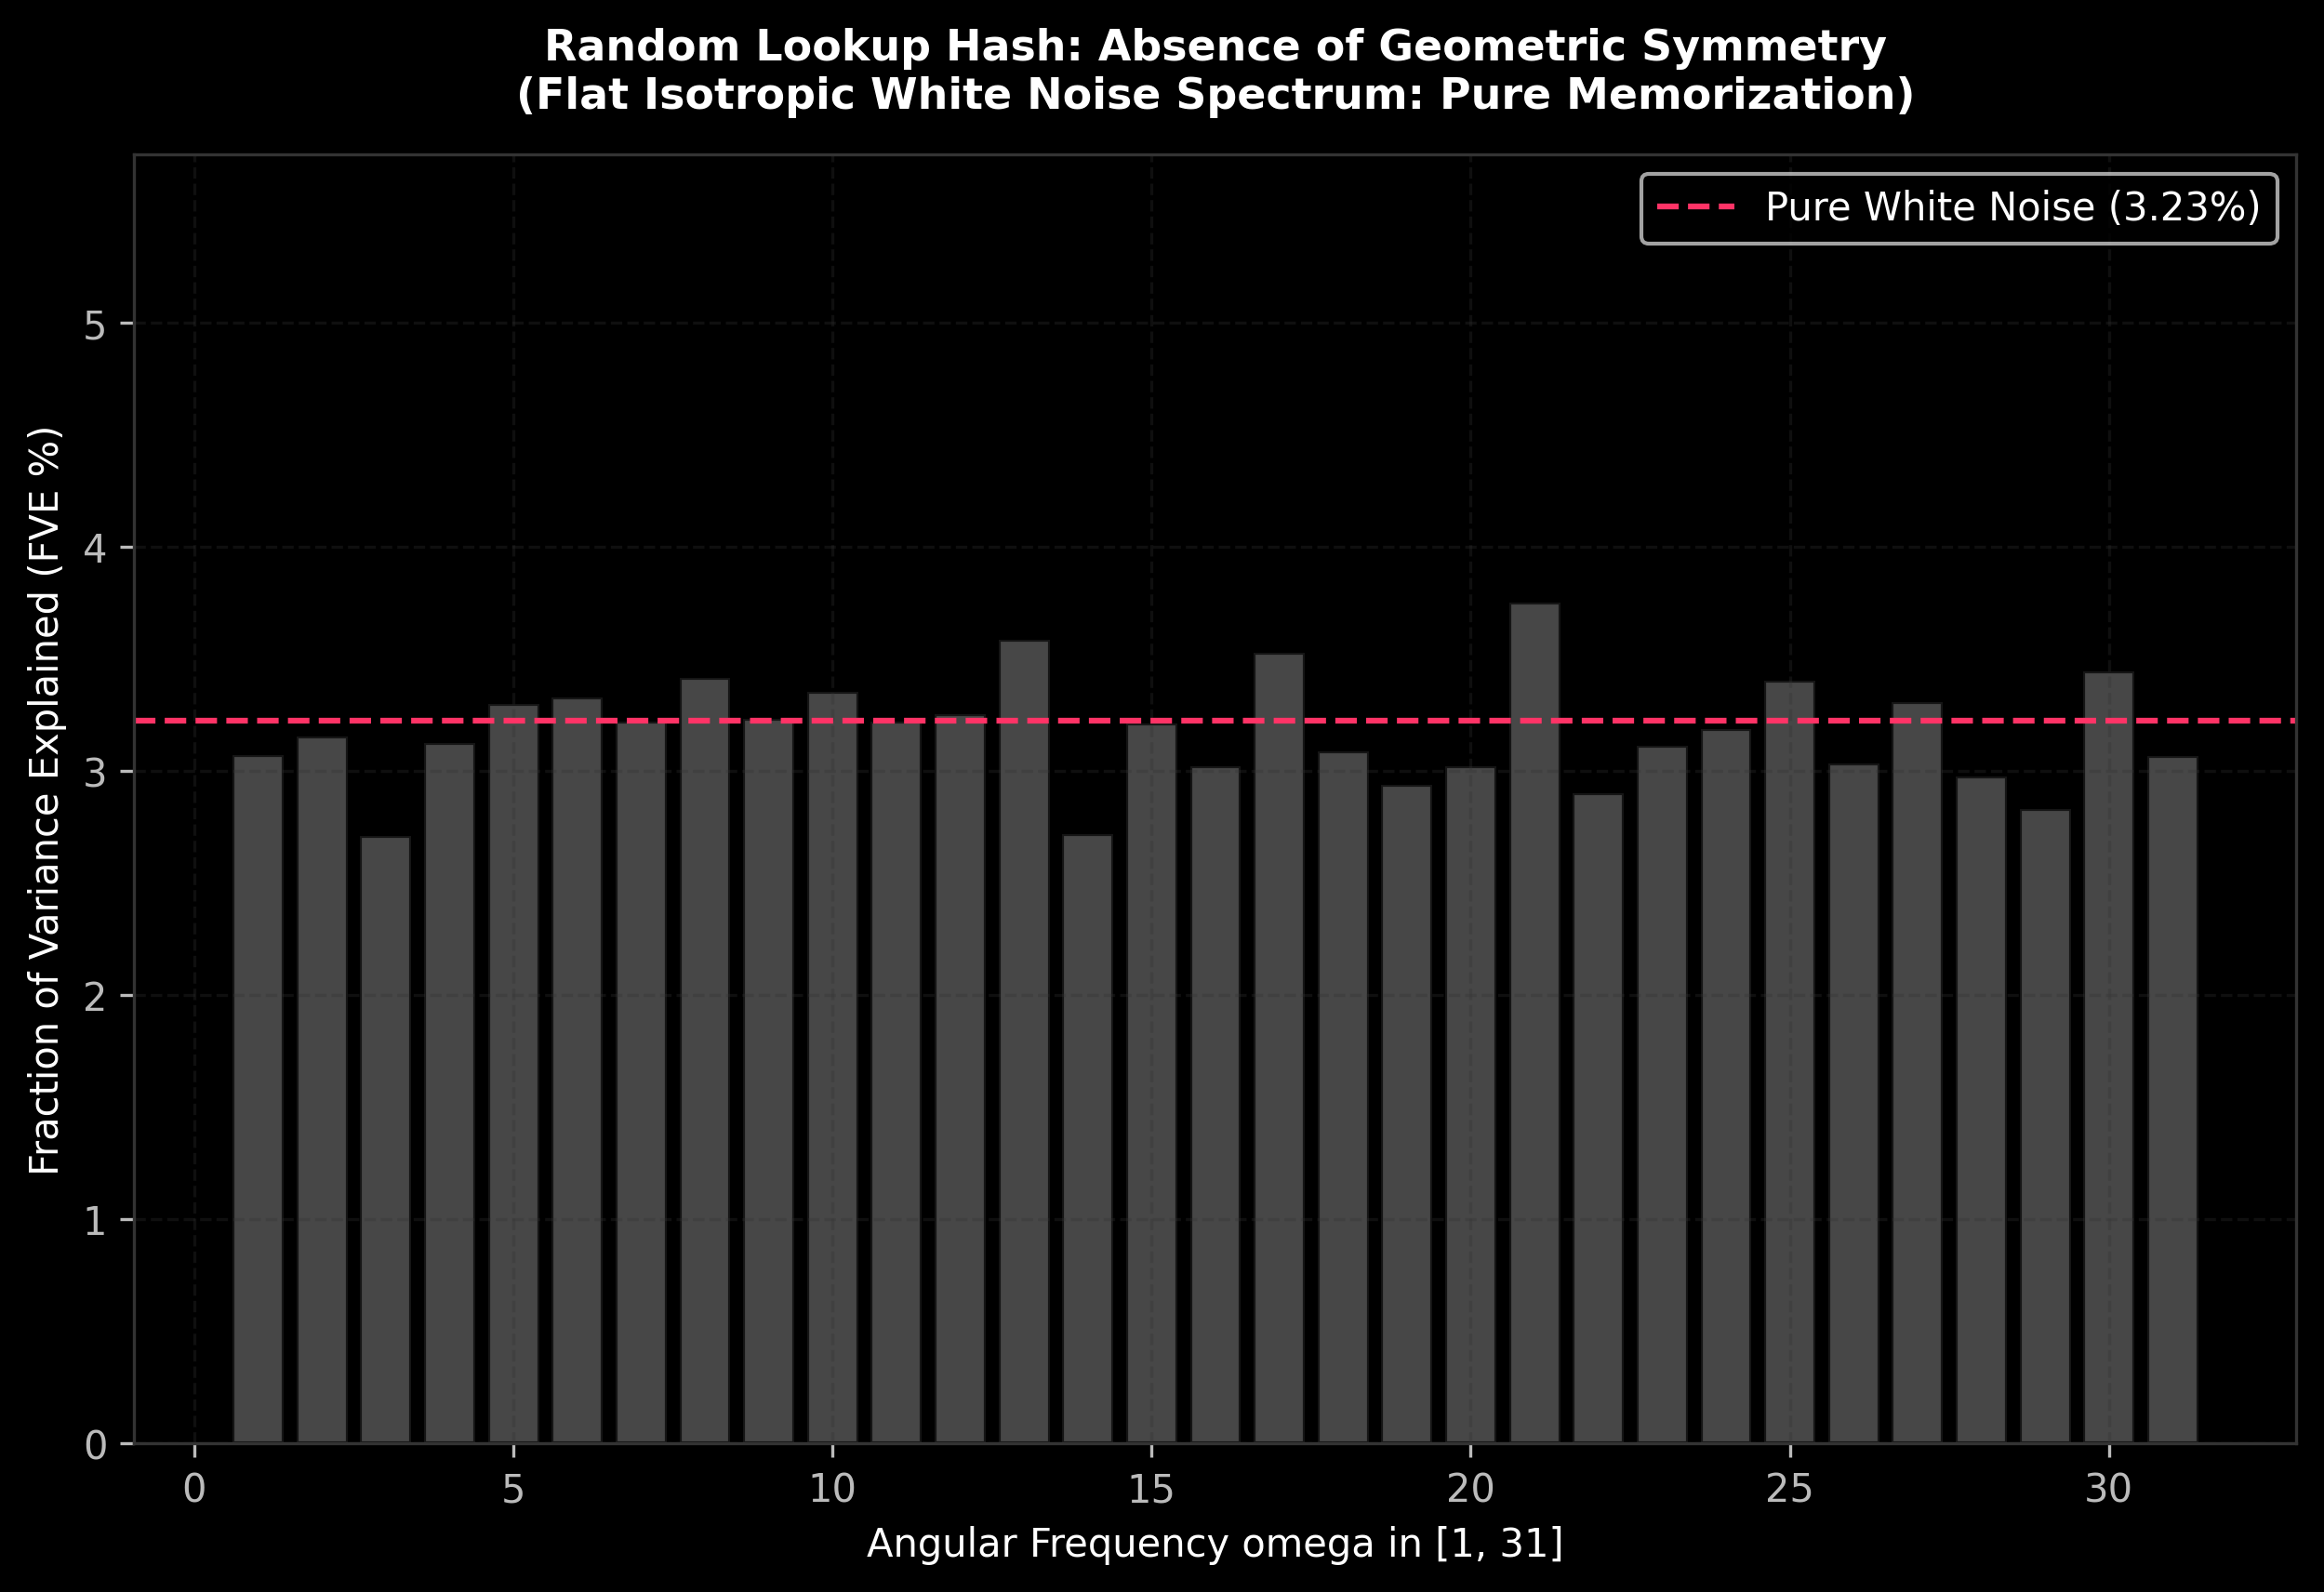

In [13]:
# @title
# =============================================================================
# BLOCK 6: RANDOM LOOKUP HASH - TRAINING & NEGATIVE CONTROL FLAT SPECTRUM
# =============================================================================
P_HASH: int = 64
MAX_STEPS_HASH: int = 2500
WEIGHT_DECAY_HASH: float = 0.0


class PLVFRandomLookupModel(nn.Module):
    vocab_size: int = P_HASH + 1
    target_classes: int = P_HASH
    d_model: int = D_MODEL
    d_inter: int = D_INTER
    n_layers: int = N_LAYERS
    m_modes: int = M_MODES
    block_size: int = 3
    dtype: jnp.dtype = DTYPE

    @nn.compact
    def __call__(self, idx: jnp.ndarray) -> Tuple[jnp.ndarray, jnp.ndarray]:
        tok_embed = self.param("token_emb", nn.initializers.normal(stddev=0.02), (self.vocab_size, self.d_model), self.dtype)
        tok_u = to_unit_sphere(tok_embed)
        x = tok_u[idx]

        for i in range(self.n_layers):
            x = PureLieVolterraFlowLayer(
                d_model=self.d_model,
                d_inter=self.d_inter,
                m_modes=self.m_modes,
                block_size=self.block_size,
                dtype=self.dtype,
                name=f"flow_{i}"
            )(x)

        last_state = to_unit_sphere(x[:, -1, :])
        target_vocab_u = tok_u[:self.target_classes, :]
        cos_sim = jnp.matmul(last_state.astype(jnp.float32), target_vocab_u.astype(jnp.float32).T)

        log_tau = self.param("log_tau", lambda rng: jnp.array(math.log(18.0), dtype=jnp.float32))
        tau = jnp.clip(jnp.exp(log_tau), 1.0, 40.0)
        logits = tau * cos_sim
        return logits, tok_u


def get_random_lookup_data(seed: int = 42) -> Tuple[jnp.ndarray, jnp.ndarray, jnp.ndarray, jnp.ndarray]:
    rng = np.random.default_rng(seed)
    random_table = rng.integers(0, P_HASH, size=(P_HASH, P_HASH))

    pairs = [(a, b) for a in range(P_HASH) for b in range(P_HASH)]
    rng.shuffle(pairs)

    n_train = len(pairs) // 2
    train_pairs, val_pairs = pairs[:n_train], pairs[n_train:]

    def build(pair_list):
        x = np.zeros((len(pair_list), 3), dtype=np.int32)
        y = np.zeros((len(pair_list),), dtype=np.int32)
        for i, (a, b) in enumerate(pair_list):
            x[i, 0], x[i, 1], x[i, 2] = a, b, P_HASH
            y[i] = random_table[a, b]
        return jnp.array(x), jnp.array(y)

    x_train, y_train = build(train_pairs)
    x_val, y_val = build(val_pairs)
    return x_train, y_train, x_val, y_val


# -----------------------------------------------------------------------------
# 1. Canonical Training Loop
# -----------------------------------------------------------------------------
x_train_hash, y_train_hash, x_val_hash, y_val_hash = get_random_lookup_data(seed=SEED)
model_hash = PLVFRandomLookupModel()

init_rng = random.PRNGKey(SEED)
dummy_x = jnp.ones((BATCH_SIZE, 3), dtype=jnp.int32)
params_hash = model_hash.init(init_rng, dummy_x)["params"]

tx_hash = optax.chain(
    optax.clip_by_global_norm(1.0),
    optax.adamw(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY_HASH, b1=0.9, b2=0.98)
)
state_hash = train_state.TrainState.create(apply_fn=model_hash.apply, params=params_hash, tx=tx_hash)


@jax.jit
def train_step_hash(state: train_state.TrainState, x: jnp.ndarray, y: jnp.ndarray):
    def loss_fn(p):
        logits, _ = state.apply_fn({"params": p}, x)
        loss = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=y).mean()
        return loss, logits
    (loss, logits), grads = jax.value_and_grad(loss_fn, has_aux=True)(state.params)
    acc = jnp.mean(jnp.argmax(logits, axis=-1) == y)
    return state.apply_gradients(grads=grads), loss, acc


train_rng = random.PRNGKey(SEED)
n_train_hash = len(x_train_hash)

for step in range(1, MAX_STEPS_HASH + 1):
    train_rng, sub_rng = random.split(train_rng)
    idx = random.randint(sub_rng, shape=(BATCH_SIZE,), minval=0, maxval=n_train_hash)
    state_hash, loss_val, acc_val = train_step_hash(state_hash, x_train_hash[idx], y_train_hash[idx])

_, tok_u_hash = state_hash.apply_fn({"params": state_hash.params}, jnp.ones((1, 3), dtype=jnp.int32))
W_E_hash = np.array(tok_u_hash[:P_HASH], dtype=np.float64)

# -----------------------------------------------------------------------------
# 2. Fourier Decomposition & Isotropic White Noise Spectrum
# -----------------------------------------------------------------------------
k_vec_hash = np.arange(P_HASH)[:, None]
max_freq_hash = (P_HASH - 1) // 2
hash_centered = W_E_hash - np.mean(W_E_hash, axis=0, keepdims=True)
tot_var_hash = np.sum(hash_centered**2)
fves_hash = []

for w in range(1, max_freq_hash + 1):
    cb = np.sqrt(2.0 / P_HASH) * np.cos(2.0 * np.pi * w * k_vec_hash / P_HASH)
    sb = np.sqrt(2.0 / P_HASH) * np.sin(2.0 * np.pi * w * k_vec_hash / P_HASH)
    energy = np.sum((cb.T @ hash_centered)**2) + np.sum((sb.T @ hash_centered)**2)
    fves_hash.append((energy / tot_var_hash) * 100.0)

omegas_hash = np.arange(1, max_freq_hash + 1)
theoretical_noise_level = 100.0 / max_freq_hash

fig_hash, ax_hash = plt.subplots(figsize=(10, 6), facecolor="#000000", dpi=300)
ax_hash.set_facecolor("#000000")

ax_hash.bar(omegas_hash, fves_hash, color="#666666", width=0.8, edgecolor="#000000", alpha=0.7)
ax_hash.axhline(
    theoretical_noise_level,
    color="#ff3366",
    linestyle="--",
    linewidth=1.5,
    label=f"Pure White Noise ({theoretical_noise_level:.2f}%)"
)

ax_hash.set_title(
    "Random Lookup Hash: Absence of Geometric Symmetry\n(Flat Isotropic White Noise Spectrum: Pure Memorization)",
    fontsize=11,
    fontweight="bold",
    pad=12
)
ax_hash.set_xlabel(f"Angular Frequency omega in [1, {max_freq_hash}]", fontsize=10)
ax_hash.set_ylabel("Fraction of Variance Explained (FVE %)", fontsize=10)
ax_hash.set_ylim(0, max(fves_hash) + 2.0)
ax_hash.legend(loc="upper right")

for spine in ax_hash.spines.values():
    spine.set_color("#333333")
ax_hash.grid(True, linestyle="--", alpha=0.3)

plt.show()